# Heurística de validación de fase — segmentación, perfil y delta de fase

Issue: [#8](https://github.com/Jacogz/DL-QPI/issues/8)

**Objetivo:** post-procesamiento de imágenes de fase para extraer métricas de validación de eritrocitos generados por el CycleGAN.

**Entregables:**
1. Segmentación de eritrocitos individuales en imágenes de fase (SAM).
2. Cálculo del perfil de fase y el delta de fase de cada eritrocito segmentado.
3. Visualización de la reconstrucción de cada eritrocito individual.
4. Anotación sobre las imágenes de fase con el perfil y delta de fase promedio.

**Requiere:** haber ejecutado `04-limpieza-fases-rbc.ipynb`, cuyo ZIP de salida (`rbc_fases_processed.zip`) debe estar en Google Drive.

---

### Nota sobre la escala de los valores de fase

Como se documentó en la sección 0.5 del notebook 04, los PNG de fase están **normalizados por recorte** (min-max de 0 a 255), no en escala fija $[-\pi, \pi]$. Por lo tanto, el delta de fase se reporta en **unidades relativas** (niveles de gris 0–255), no en radianes.

## 0. Setup

In [1]:
# Instalar SAM (Segment Anything Model)
!pip install -q segment-anything

# Descargar checkpoint SAM ViT-B (aprox 375 MB) suficiente para parches 256×256
import os
SAM_CKPT = 'sam_vit_b_01ec64.pth'
if not os.path.exists(SAM_CKPT):
    !wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth
    print(f'Descargado: {SAM_CKPT}')
else:
    print(f'Ya existe: {SAM_CKPT}')

Descargado: sam_vit_b_01ec64.pth


In [2]:
import json
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import torch
from PIL import Image
from scipy import ndimage as ndi
from skimage import measure
from tqdm.auto import tqdm

from segment_anything import sam_model_registry, SamAutomaticMaskGenerator

print(f'PyTorch {torch.__version__}, CUDA disponible: {torch.cuda.is_available()}')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Dispositivo: {DEVICE}')

PyTorch 2.14.1+cu130, CUDA disponible: True
Dispositivo: cuda


## 1. Carga de datos desde Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

# Rutas
DRIVE_ZIP = Path('/content/drive/MyDrive/dl-qpi/data/processed/rbc_fases_processed.zip')
DATA_DIR  = Path('/content/data/processed/rbc_fases_processed')

# Descomprimir si no existe ya
if not DATA_DIR.is_dir():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(DRIVE_ZIP, 'r') as zf:
        zf.extractall(DATA_DIR)
    print(f'Descomprimido en {DATA_DIR}')
else:
    print(f'Ya existe: {DATA_DIR}')

# Buscar manifest.csv (puede estar en la raíz o un nivel adentro)
manifest_candidates = list(DATA_DIR.rglob('manifest.csv'))
assert manifest_candidates, f'No se encontró manifest.csv en {DATA_DIR}'
MANIFEST_PATH = manifest_candidates[0]
IMG_ROOT = MANIFEST_PATH.parent  # las rutas en manifest son relativas a esta carpeta
print(f'Manifest: {MANIFEST_PATH}')
print(f'Raíz de imágenes: {IMG_ROOT}')

Mounted at /content/drive
Descomprimido en /content/data/processed/rbc_fases_processed
Manifest: /content/data/processed/rbc_fases_processed/manifest.csv
Raíz de imágenes: /content/data/processed/rbc_fases_processed


In [4]:
# Cargar manifiesto
manifest = pd.read_csv(MANIFEST_PATH)
manifest['cell_boxes'] = manifest['cell_boxes'].apply(json.loads)
manifest['n_cells'] = manifest['cell_boxes'].apply(len)

print(f'Recortes totales: {len(manifest)}')
print(manifest.groupby('split').agg(
    recortes=('file', 'size'),
    celulas_mediana=('n_cells', 'median')
))
manifest.head()

Recortes totales: 2734
            recortes  celulas_mediana
split                                
Training        2292              6.0
Validation       442              6.0


,file,split,source,a,b,split_paper,file_paper,bg_gray,n_cells,cell_boxes
0,Training/Image__2021-01-28__15-49-02_1-10.png,Training,Image__2021-01-28__15-49-02,1,10,Training,Image__2021-01-28__15-49-02_1-10.png.png.png,129.0,4,"[[13, 139, 67, 191], [123, 173, 176, 224], [20..."
1,Training/Image__2021-01-28__15-49-02_1-13.png,Training,Image__2021-01-28__15-49-02,1,13,Training,Image__2021-01-28__15-49-02_1-13.png.png.png,109.0,5,"[[20, 137, 68, 186], [42, 0, 91, 21], [136, 38..."
2,Training/Image__2021-01-28__15-49-02_1-14.png,Training,Image__2021-01-28__15-49-02,1,14,Training,Image__2021-01-28__15-49-02_1-14.png.png.png,149.0,3,"[[0, 0, 256, 256], [150, 81, 197, 126], [203, ..."
3,Training/Image__2021-01-28__15-49-02_1-2.png,Training,Image__2021-01-28__15-49-02,1,2,Training,Image__2021-01-28__15-49-02_1-2.png.png.png,90.0,3,"[[0, 108, 45, 156], [50, 191, 105, 245], [175,..."
4,Training/Image__2021-01-28__15-49-02_1-4.png,Training,Image__2021-01-28__15-49-02,1,4,Training,Image__2021-01-28__15-49-02_1-4.png.png.png,116.0,5,"[[24, 175, 80, 226], [26, 234, 73, 256], [120,..."


In [5]:
# Seleccionar ≥ 5 imágenes de muestra con buen número de células
SEED = 42
N_SAMPLE = 8  # usar 8 para tener margen, mínimo 5

# Filtrar imágenes con al menos 2 células (para que el perfil sea interesante)
candidates = manifest[manifest['n_cells'] >= 2].copy()
sample_df = candidates.sample(n=min(N_SAMPLE, len(candidates)), random_state=SEED)
sample_df = sample_df.reset_index(drop=True)

print(f'Imágenes seleccionadas: {len(sample_df)}')
for i, row in sample_df.iterrows():
    print(f'  [{i}] {row["file"]}  ({row["n_cells"]} células detectadas en nb04)')

Imágenes seleccionadas: 8
  [0] Training/Image__2021-01-29__12-36-21_4-3.png  (5 células detectadas en nb04)
  [1] Training/Image__2021-01-29__13-12-01_4-1.png  (4 células detectadas en nb04)
  [2] Training/Image__2021-01-29__13-26-59_3-8.png  (5 células detectadas en nb04)
  [3] Training/Image__2021-01-29__13-12-01_4-11.png  (3 células detectadas en nb04)
  [4] Training/Image__2021-01-29__13-12-45_2-1.png  (2 células detectadas en nb04)
  [5] Training/Image__2021-01-28__16-04-31_3-3.png  (4 células detectadas en nb04)
  [6] Validation/Image__2021-01-29__13-15-19_3-6.png  (9 células detectadas en nb04)
  [7] Training/Image__2021-01-29__12-53-41_1-6.png  (8 células detectadas en nb04)


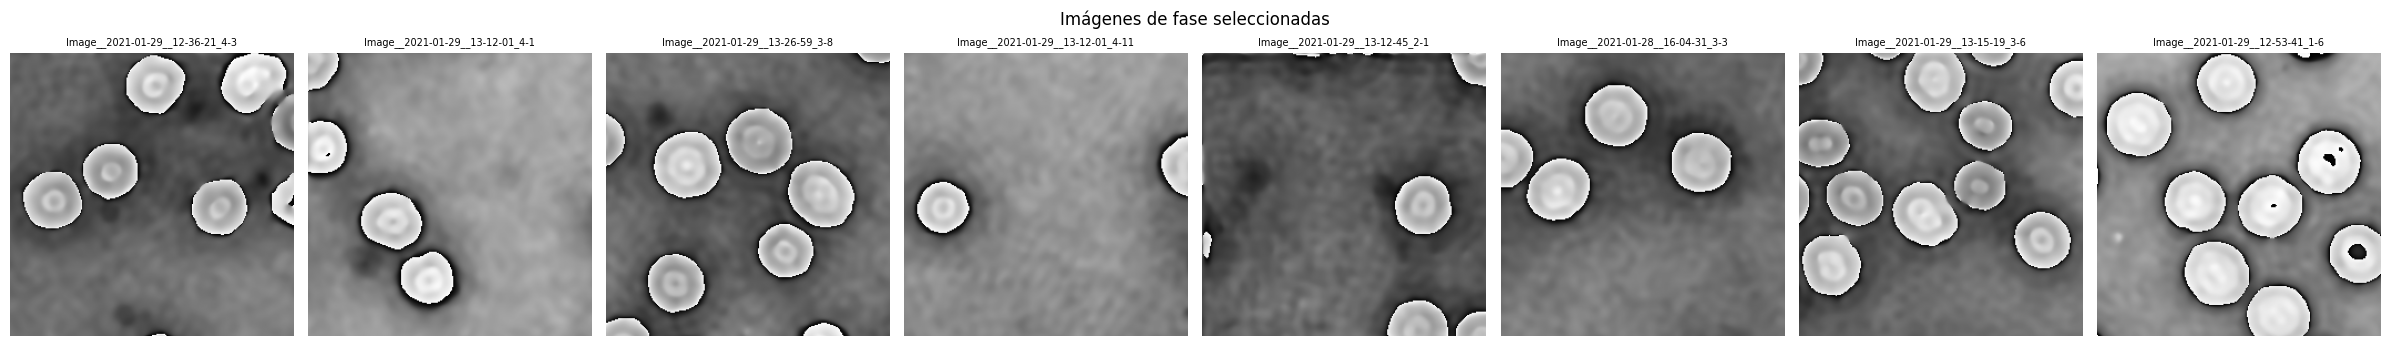

In [6]:
# Vista rápida de las imágenes seleccionadas
n = len(sample_df)
fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.5), squeeze=False)
for i, (_, row) in enumerate(sample_df.iterrows()):
    img = np.array(Image.open(IMG_ROOT / row['file']).convert('L'))
    axes[0][i].imshow(img, cmap='gray', vmin=0, vmax=255)
    axes[0][i].set_title(Path(row['file']).stem, fontsize=7)
    axes[0][i].axis('off')
plt.suptitle('Imágenes de fase seleccionadas', fontsize=12)
plt.tight_layout()
plt.show()

## 2. Inicializar SAM

In [7]:
sam = sam_model_registry['vit_b'](checkpoint=SAM_CKPT)
sam = sam.to(DEVICE)
sam.eval()

mask_generator = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=32,          # densidad de la grilla de prompts
    pred_iou_thresh=0.86,        # umbral de confianza de IoU
    stability_score_thresh=0.92, # estabilidad de la máscara
    min_mask_region_area=200,    # área mínima en píxeles
)
print('SAM inicializado correctamente.')

SAM inicializado correctamente.


## 3. Funciones auxiliares

In [8]:
# Conversión de intensidad a fase (relativa)
# Los PNG están normalizados min-max por recorte (ver notebook 04, sección 0.5)
# Mapeamos 0–255 a [-1, 1] para el cálculo de perfiles, como se acordó para el DataLoader

def to_phase(gray: np.ndarray) -> np.ndarray:
    """Convierte imagen 8-bit (0–255) a fase relativa [-1, 1]."""
    return (gray.astype(np.float64) / 255.0) * 2.0 - 1.0


def to_phase_norm(gray: np.ndarray) -> np.ndarray:
    """Convierte imagen 8-bit a [0, 1] para visualización."""
    return gray.astype(np.float64) / 255.0

In [9]:
# Filtrado de máscaras SAM
def circularity(mask: np.ndarray) -> float:
    """Calcula la circularidad de una máscara binaria (1.0 = círculo perfecto)."""
    contours, _ = cv2.findContours(
        mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    if not contours:
        return 0.0
    c = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(c)
    perimeter = cv2.arcLength(c, True)
    if perimeter == 0:
        return 0.0
    return 4 * np.pi * area / (perimeter ** 2)


def touches_border(mask: np.ndarray, margin: int = 2) -> bool:
    """Verifica si la máscara toca el borde de la imagen."""
    h, w = mask.shape
    return (
        mask[:margin, :].any() or mask[-margin:, :].any() or
        mask[:, :margin].any() or mask[:, -margin:].any()
    )


def filter_cell_masks(
    sam_masks: list,
    min_area: int = 300,
    max_area: int = 5000,
    min_circ: float = 0.50,
) -> list:
    """
    Filtra las máscaras de SAM para quedarse solo con eritrocitos plausibles.
    Criterios: rango de área, circularidad mínima y que no toque el borde.
    """
    valid = []
    for m in sam_masks:
        seg = m['segmentation']
        area = seg.sum()
        if not (min_area <= area <= max_area):
            continue
        if circularity(seg) < min_circ:
            continue
        if touches_border(seg):
            continue
        valid.append(m)
    return valid

In [10]:
# Extracción de perfil de fase

def extract_phase_profile(phi: np.ndarray, mask: np.ndarray):
    """
    Extrae el perfil de fase a lo largo del diámetro horizontal del eritrocito.

    Parámetros
    ----------
    phi : ndarray
        Imagen de fase completa (valores en [-1, 1]).
    mask : ndarray (bool)
        Máscara binaria de un eritrocito individual.

    Retorna
    -------
    profile : ndarray 1-D
        Valores de fase corregidos por fondo a lo largo del diámetro.
    delta_phi : float
        Diferencia máx – mín del perfil.
    centroid : tuple (cy, cx)
        Coordenadas del centroide de la máscara.
    bg_value : float
        Valor mediano del fondo usado para la corrección.
    """
    # Centroide
    moments = cv2.moments(mask.astype(np.uint8))
    if moments['m00'] == 0:
        return np.array([]), 0.0, (0, 0), 0.0
    cy = int(moments['m01'] / moments['m00'])
    cx = int(moments['m10'] / moments['m00'])

    # Fondo: mediana de la fase fuera de todas las células (se pasa phi completa)
    bg_value = np.median(phi[~mask])

    # Perfil horizontal en la fila del centroide, solo dentro de la máscara
    row_vals = phi[cy, :]
    row_mask = mask[cy, :]
    profile = row_vals[row_mask] - bg_value

    delta_phi = float(profile.max() - profile.min()) if len(profile) > 2 else 0.0

    return profile, delta_phi, (cy, cx), bg_value


def extract_phase_profile_bg_global(phi: np.ndarray, cell_mask: np.ndarray, all_cells_mask: np.ndarray):
    """
    Igual que extract_phase_profile pero usa una máscara global de todas las
    células para calcular el fondo (más preciso cuando hay varias células).
    """
    moments = cv2.moments(cell_mask.astype(np.uint8))
    if moments['m00'] == 0:
        return np.array([]), 0.0, (0, 0), 0.0
    cy = int(moments['m01'] / moments['m00'])
    cx = int(moments['m10'] / moments['m00'])

    # Fondo: mediana fuera de todas las células
    bg_pixels = phi[~all_cells_mask]
    bg_value = np.median(bg_pixels) if len(bg_pixels) > 0 else 0.0

    # Perfil horizontal
    row_vals = phi[cy, :]
    row_mask = cell_mask[cy, :]
    profile = row_vals[row_mask] - bg_value

    delta_phi = float(profile.max() - profile.min()) if len(profile) > 2 else 0.0

    return profile, delta_phi, (cy, cx), bg_value

In [11]:
# Visualización individual de un eritrocito

def plot_cell_panel(
    phi: np.ndarray,
    mask: np.ndarray,
    profile: np.ndarray,
    delta_phi: float,
    centroid: tuple,
    cell_id: int,
    img_name: str,
):
    """
    Muestra un panel de 3 columnas para un eritrocito:
      - Izquierda: recorte de fase con contorno de la máscara.
      - Centro: mapa de fase aislado del eritrocito.
      - Derecha: perfil de fase 1-D con delta anotado.
    """
    cy, cx = centroid
    y_idx, x_idx = np.where(mask)
    pad = 10
    r0, r1 = max(0, y_idx.min() - pad), min(phi.shape[0], y_idx.max() + pad)
    c0, c1 = max(0, x_idx.min() - pad), min(phi.shape[1], x_idx.max() + pad)

    crop_phi = phi[r0:r1, c0:c1]
    crop_mask = mask[r0:r1, c0:c1]

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    # Panel 1: fase + contorno
    axes[0].imshow(crop_phi, cmap='inferno')
    axes[0].contour(crop_mask.astype(np.uint8), levels=[0.5], colors='lime', linewidths=1.5)
    axes[0].set_title(f'Eritrocito {cell_id}\n{img_name}', fontsize=9)
    axes[0].axis('off')

    # Panel 2: fase aislada
    phi_isolated = np.where(crop_mask, crop_phi, np.nan)
    axes[1].imshow(phi_isolated, cmap='inferno')
    axes[1].set_title('Fase aislada', fontsize=9)
    axes[1].axis('off')

    # Panel 3: perfil 1-D
    if len(profile) > 2:
        x_px = np.arange(len(profile))
        axes[2].plot(x_px, profile, color='steelblue', lw=1.5, label='Perfil')
        axes[2].axhline(profile.max(), color='red', ls='--', lw=0.8, label=f'máx = {profile.max():.3f}')
        axes[2].axhline(profile.min(), color='blue', ls='--', lw=0.8, label=f'mín = {profile.min():.3f}')
        axes[2].fill_between(x_px, profile.min(), profile, alpha=0.15, color='steelblue')
        axes[2].set_title(f'Perfil de fase — Δφ = {delta_phi:.4f}', fontsize=9)
        axes[2].set_xlabel('Píxel (diámetro)')
        axes[2].set_ylabel('φ (relativa, corregida por fondo)')
        axes[2].legend(fontsize=7, loc='best')
    else:
        axes[2].text(0.5, 0.5, 'Perfil insuficiente\n(< 3 px)', ha='center', va='center', fontsize=10)
        axes[2].set_title('Perfil de fase — sin datos')

    plt.tight_layout()
    plt.show()
    plt.close(fig)

In [12]:
# Anotación de imagen completa

def annotate_image(
    phi: np.ndarray,
    cell_masks: list,
    deltas: list,
    profiles: list,
    centroids: list,
    img_name: str,
    save_dir: Path = None,
):
    """
    Genera una imagen anotada con contornos numerados y un panel lateral
    con el perfil de fase promedio y el delta promedio.
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 6),
                             gridspec_kw={'width_ratios': [1, 0.8]})

    # Panel izquierdo: imagen anotada
    ax_img = axes[0]
    ax_img.imshow(phi, cmap='inferno')

    colors = plt.cm.Set1(np.linspace(0, 1, max(len(cell_masks), 1)))
    for i, (m, dp) in enumerate(zip(cell_masks, deltas)):
        seg = m['segmentation'].astype(np.uint8)
        contours_cv, _ = cv2.findContours(seg, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for cnt in contours_cv:
            pts = cnt.squeeze()
            if pts.ndim == 2 and len(pts) >= 3:
                polygon = plt.Polygon(pts, fill=False,
                                      edgecolor=colors[i % len(colors)],
                                      linewidth=2)
                ax_img.add_patch(polygon)
        cy, cx = centroids[i]
        ax_img.text(cx, cy, str(i + 1), color='white', fontsize=8,
                    ha='center', va='center',
                    bbox=dict(boxstyle='round,pad=0.2', fc='black', alpha=0.6))

    mean_delta = np.mean(deltas) if deltas else 0.0
    std_delta = np.std(deltas) if len(deltas) > 1 else 0.0
    ax_img.set_title(
        f'{img_name}\n'
        f'n = {len(cell_masks)} células | '
        f'Δφ prom = {mean_delta:.4f} ± {std_delta:.4f}',
        fontsize=10
    )
    ax_img.axis('off')

    # Panel derecho: perfil de fase promedio
    ax_prof = axes[1]
    if profiles:
        # Interpolar todos los perfiles a la misma longitud para promediar
        max_len = max(len(p) for p in profiles)
        interp_profiles = []
        for p in profiles:
            if len(p) > 2:
                x_orig = np.linspace(0, 1, len(p))
                x_new = np.linspace(0, 1, max_len)
                interp_profiles.append(np.interp(x_new, x_orig, p))
        if interp_profiles:
            stacked = np.array(interp_profiles)
            mean_profile = stacked.mean(axis=0)
            std_profile = stacked.std(axis=0)
            x_px = np.arange(max_len)

            # Perfiles individuales (transparentes)
            for j, ip in enumerate(interp_profiles):
                ax_prof.plot(x_px, ip, color=colors[j % len(colors)],
                             alpha=0.3, lw=0.8)

            # Promedio ± std
            ax_prof.plot(x_px, mean_profile, color='black', lw=2, label='Promedio')
            ax_prof.fill_between(x_px,
                                 mean_profile - std_profile,
                                 mean_profile + std_profile,
                                 alpha=0.2, color='gray', label='± 1 std')
            ax_prof.legend(fontsize=8)
            ax_prof.set_title(f'Perfil promedio\nΔφ prom = {mean_delta:.4f}', fontsize=10)
        else:
            ax_prof.text(0.5, 0.5, 'Sin perfiles válidos', ha='center', va='center')
            ax_prof.set_title('Perfil promedio')
    else:
        ax_prof.text(0.5, 0.5, 'Sin células detectadas', ha='center', va='center')
        ax_prof.set_title('Perfil promedio')

    ax_prof.set_xlabel('Posición normalizada (diámetro)')
    ax_prof.set_ylabel('φ (relativa)')

    plt.tight_layout()

    if save_dir is not None:
        save_dir.mkdir(parents=True, exist_ok=True)
        save_path = save_dir / f'annotated_{Path(img_name).stem}.png'
        fig.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f'  Guardado: {save_path}')

    plt.show()
    plt.close(fig)

    return mean_delta, std_delta

## 4. Segmentación y análisis — loop principal

Para cada imagen de muestra:
1. Se ejecuta SAM para generar máscaras automáticas.
2. Se filtran las máscaras por área, circularidad y contacto con el borde.
3. Se calcula el fondo global (mediana fuera de todas las células) y se extrae el perfil de fase por eritrocito.
4. Se muestra el panel individual por célula.
5. Se genera la imagen anotada con promedios.


Imagen 1/8: Image__2021-01-29__12-36-21_4-3.png
  Máscaras SAM crudas: 21
  Eritrocitos válidos: 8


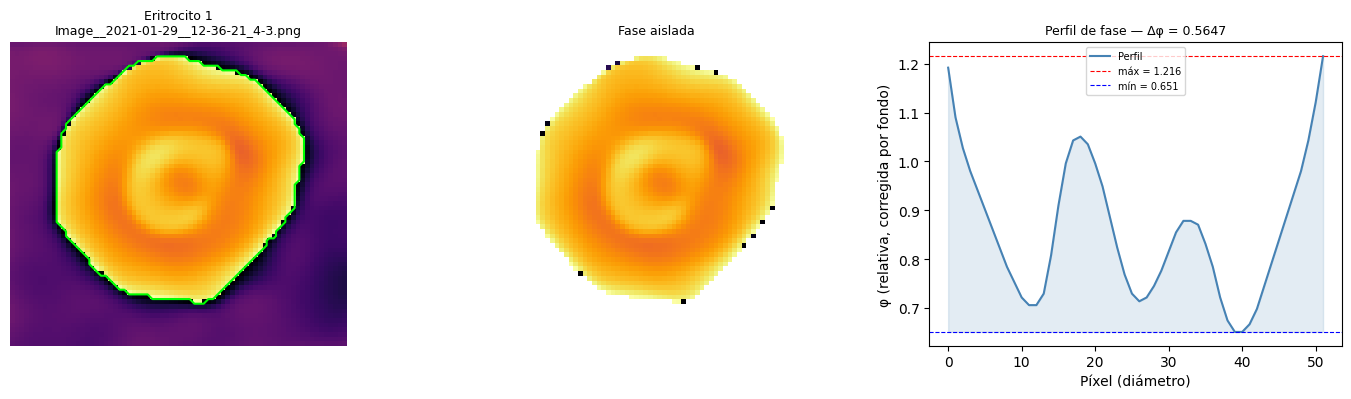

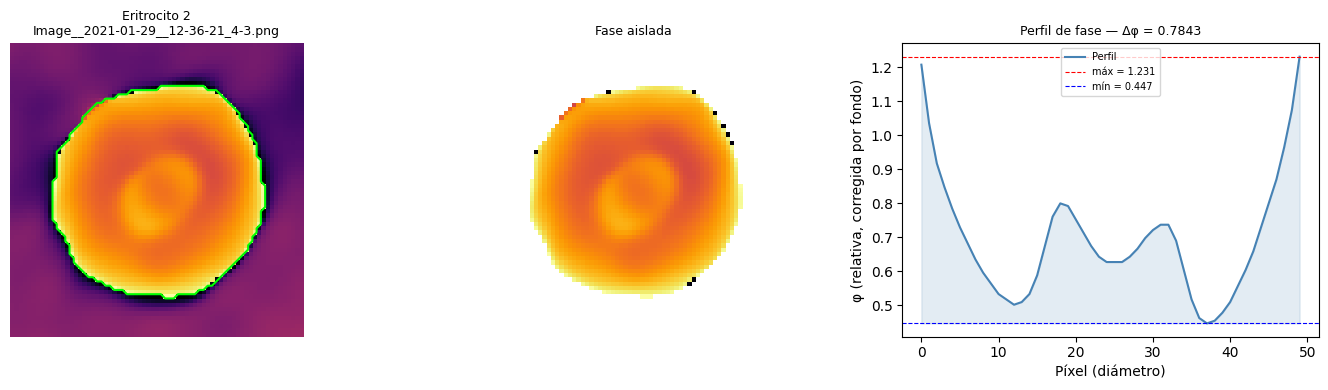

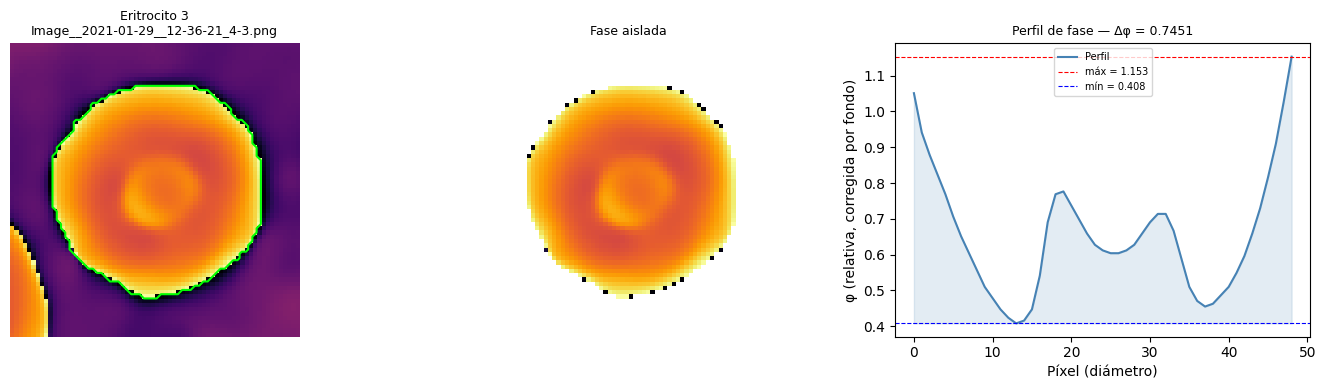

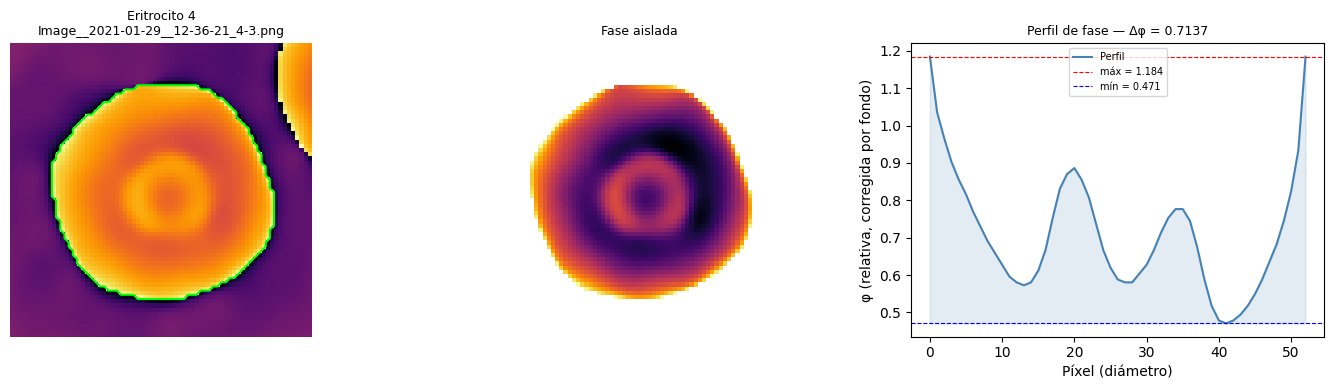

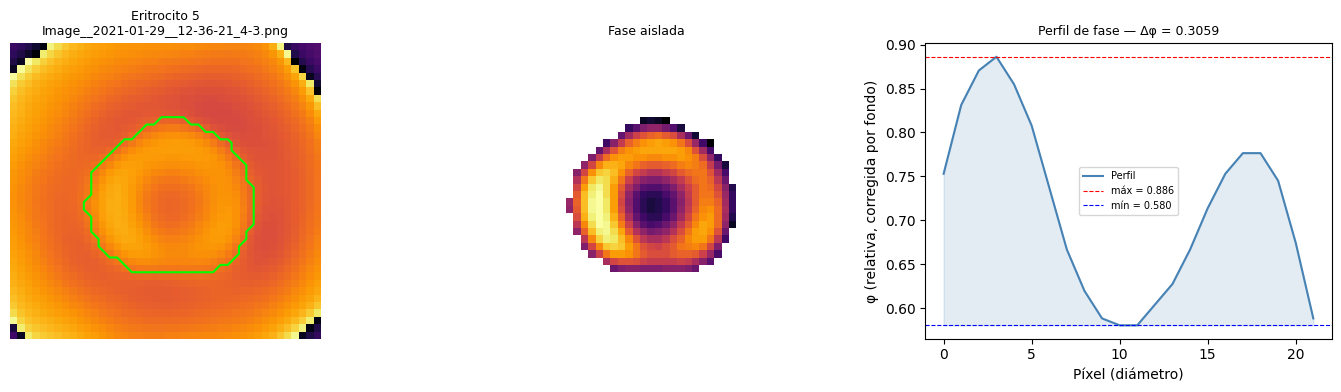

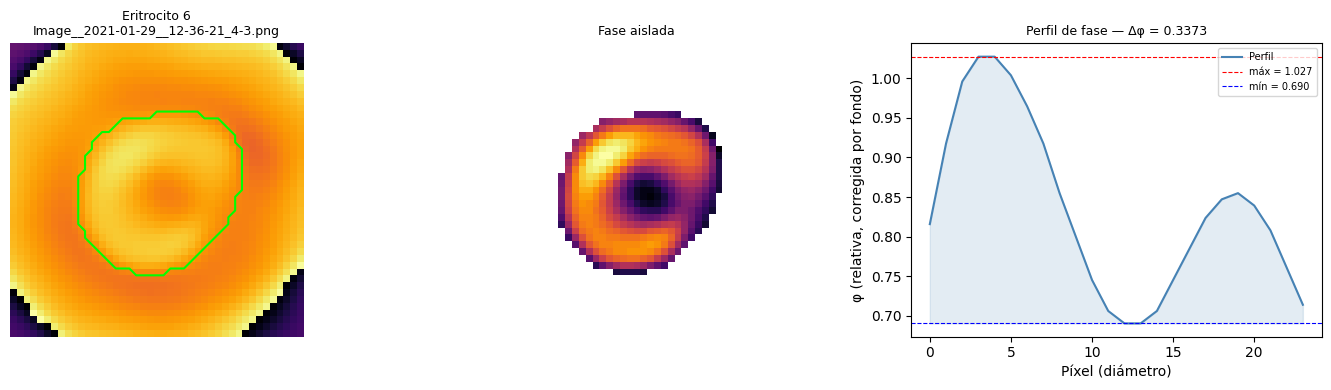

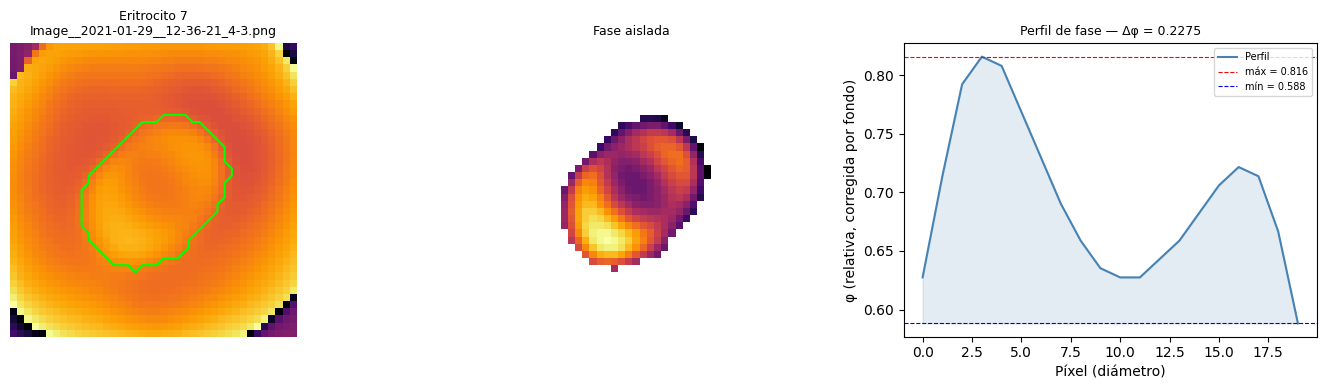

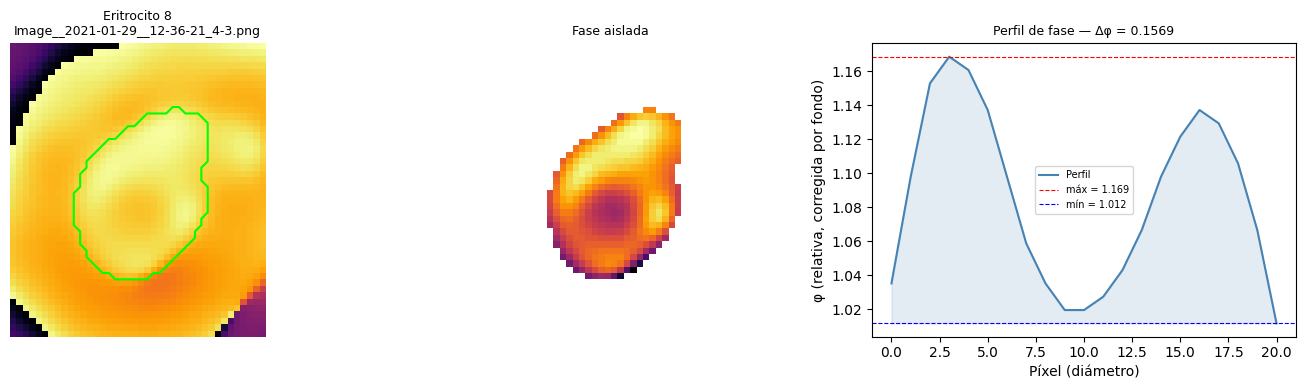

  Guardado: /content/data/processed/heuristica_validacion/annotated_Image__2021-01-29__12-36-21_4-3.png


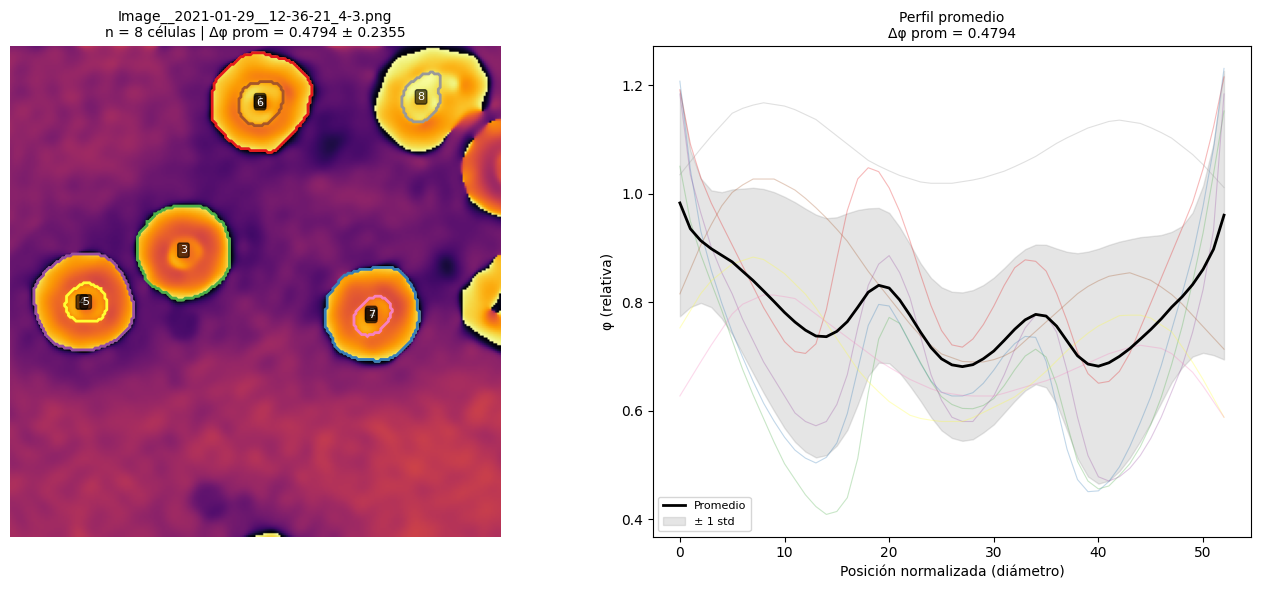


Imagen 2/8: Image__2021-01-29__13-12-01_4-1.png
  Máscaras SAM crudas: 9
  Eritrocitos válidos: 4


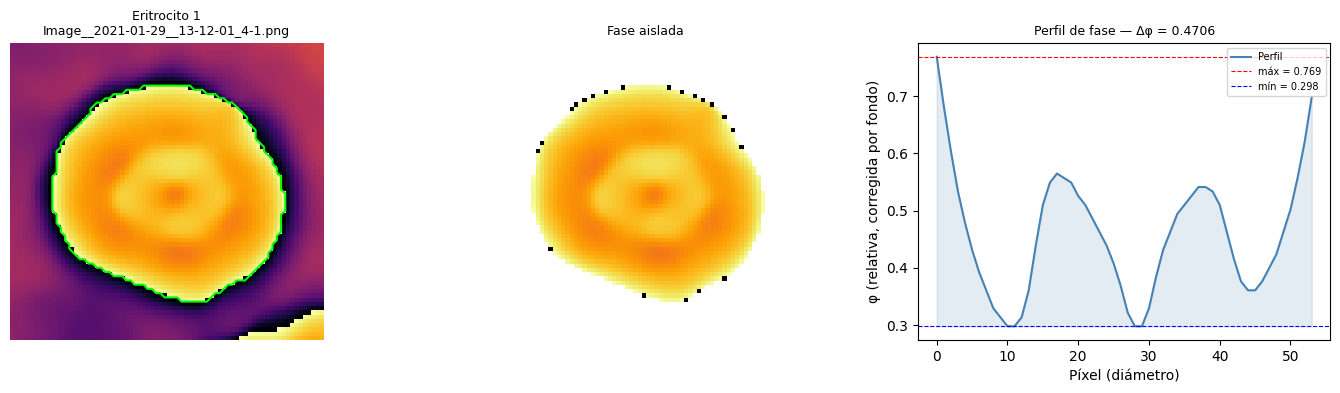

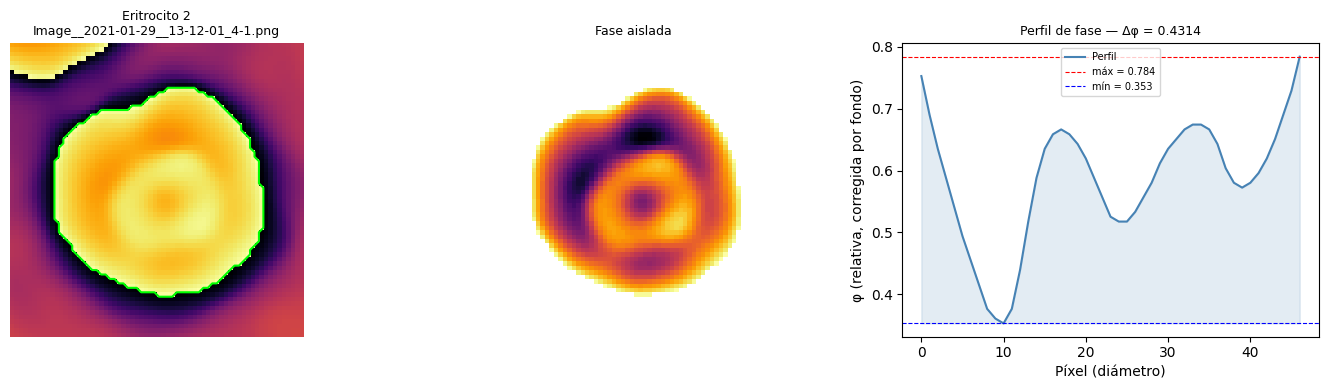

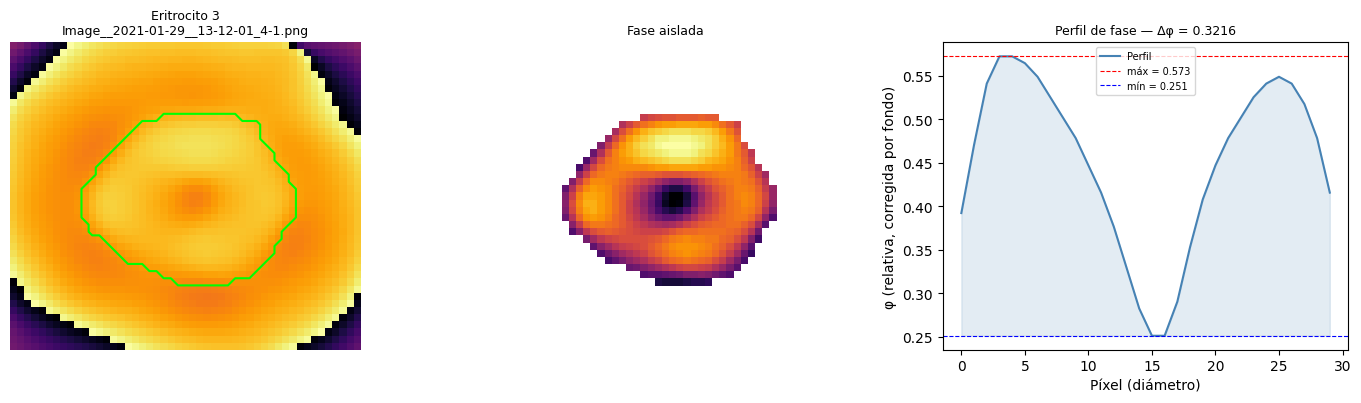

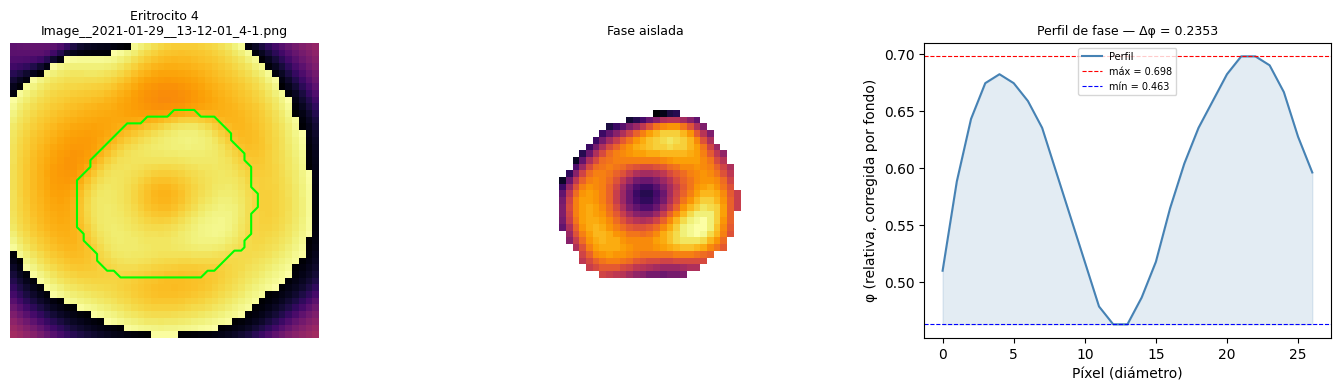

  Guardado: /content/data/processed/heuristica_validacion/annotated_Image__2021-01-29__13-12-01_4-1.png


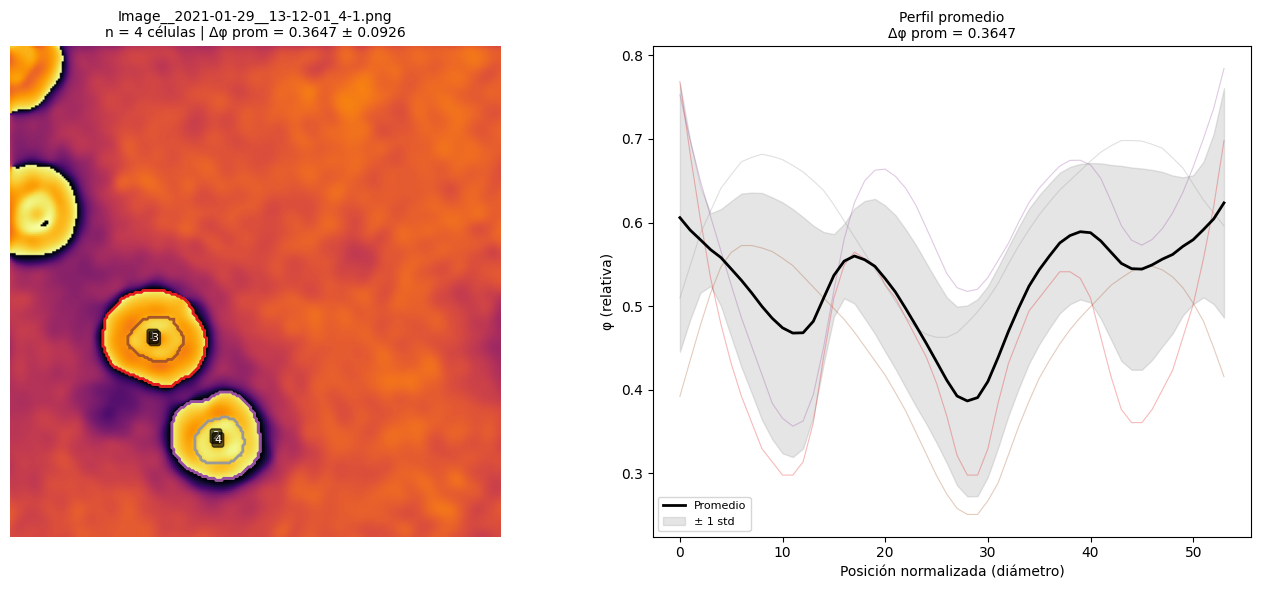


Imagen 3/8: Image__2021-01-29__13-26-59_3-8.png
  Máscaras SAM crudas: 20
  Eritrocitos válidos: 11


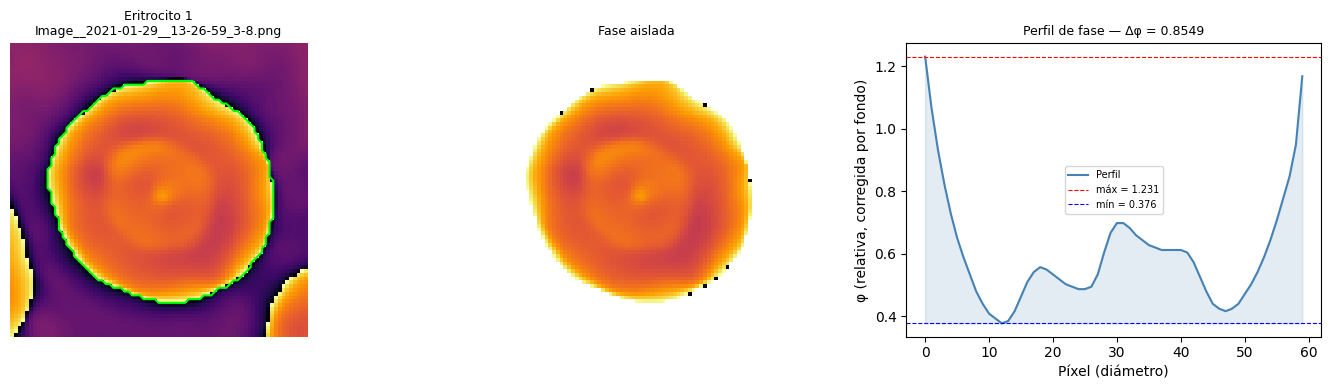

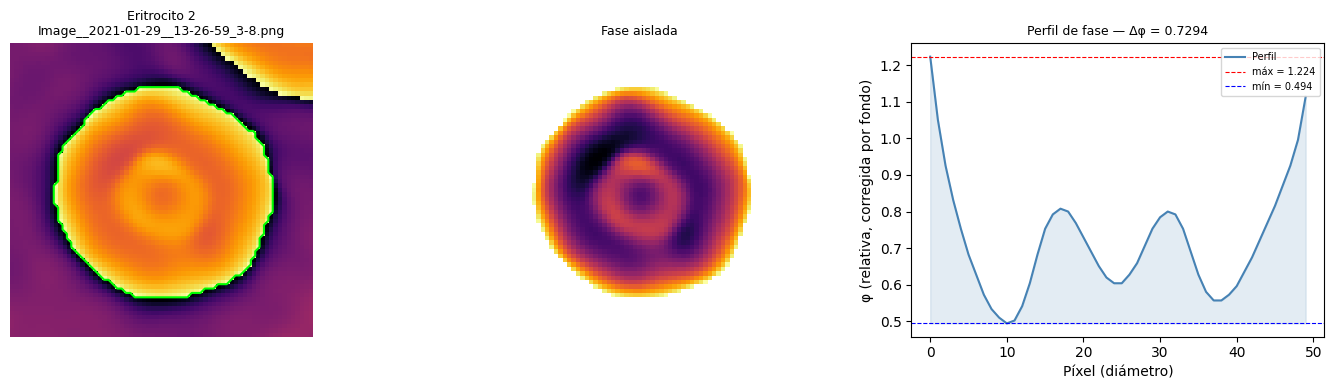

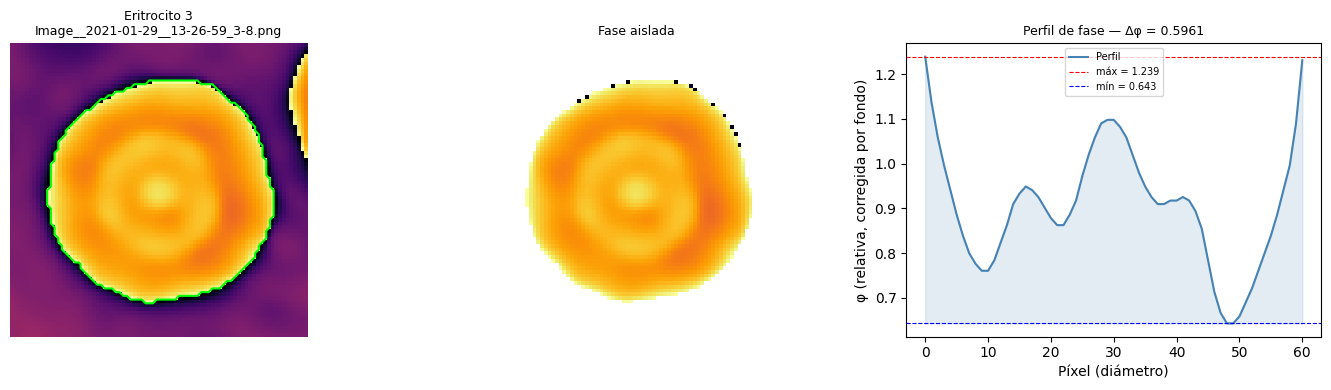

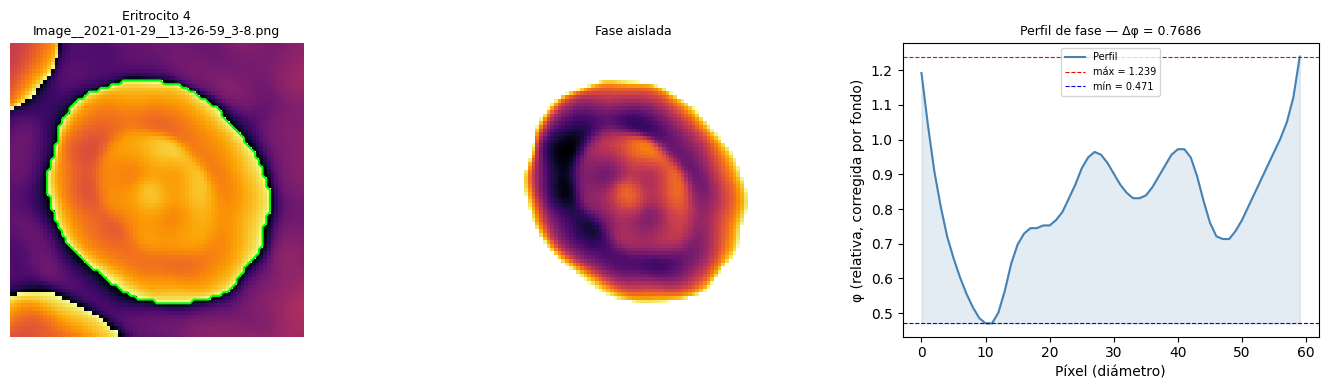

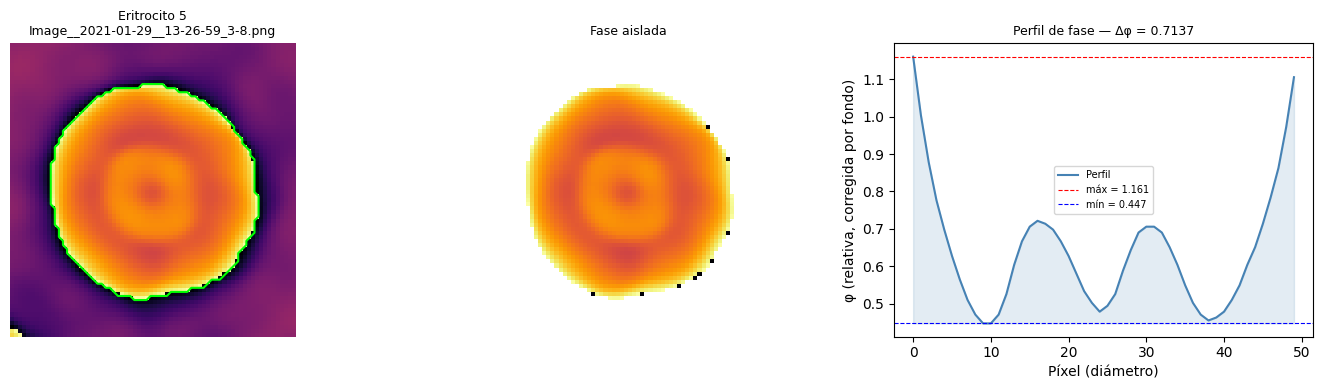

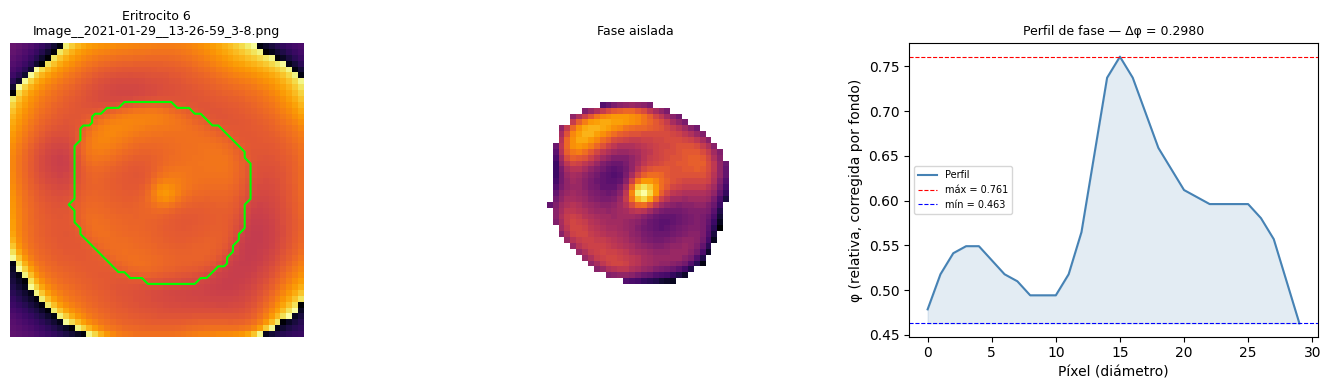

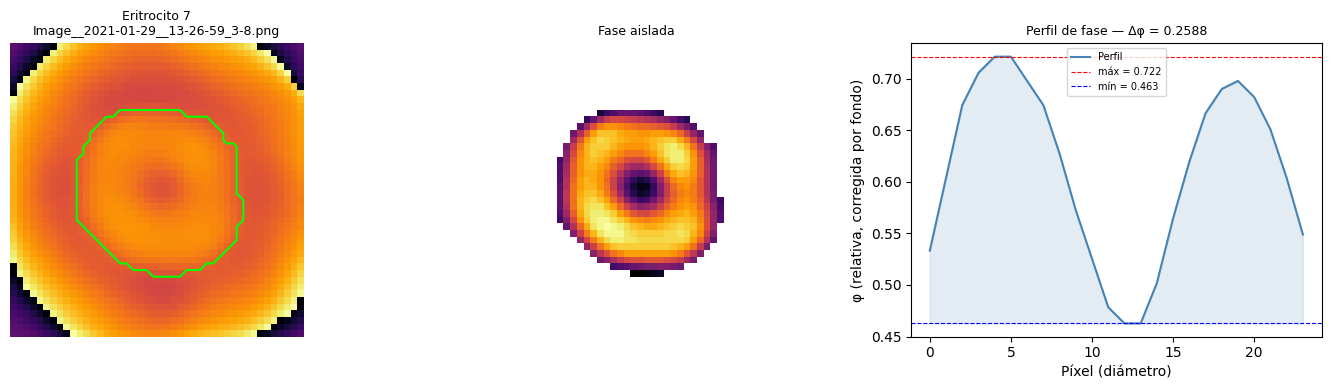

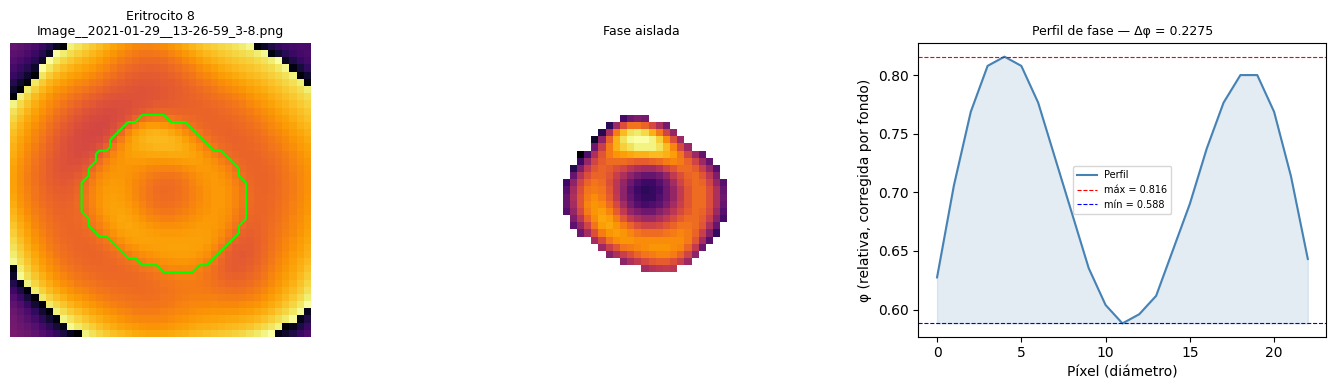

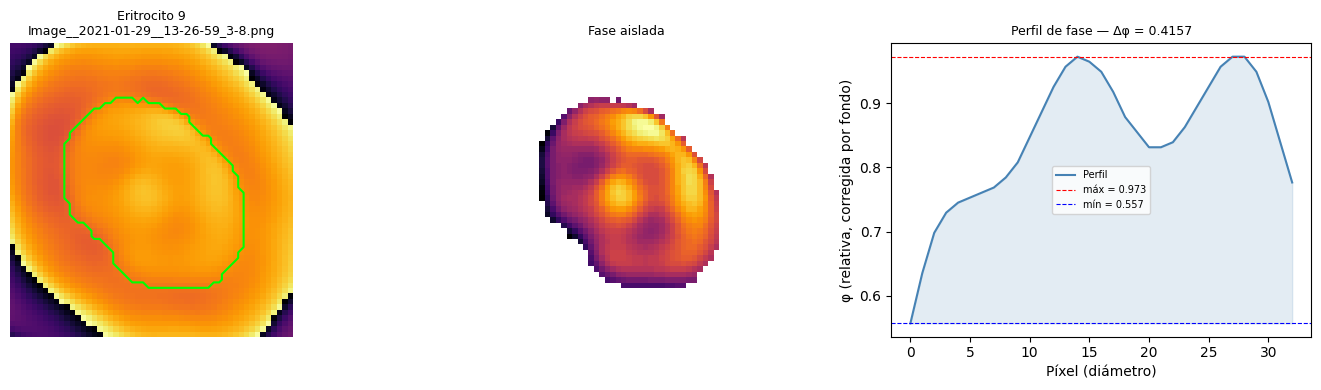

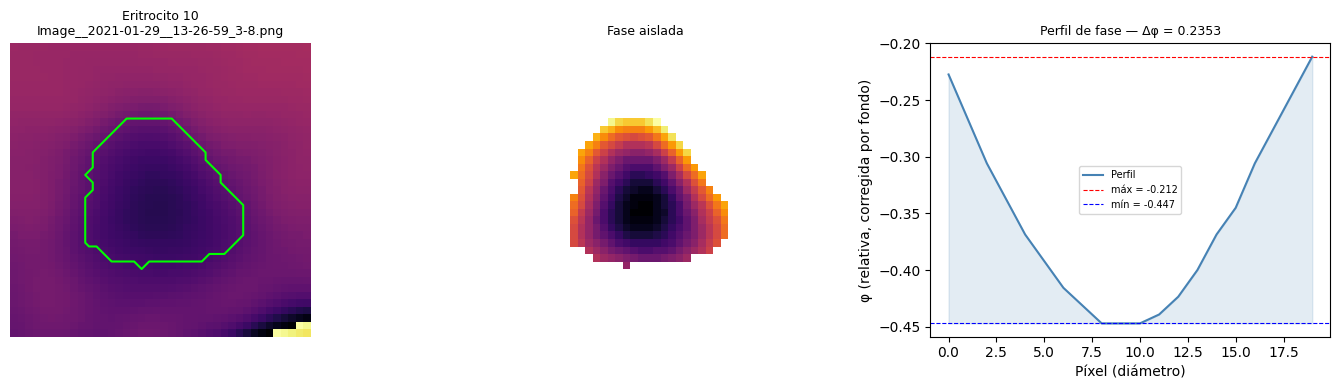

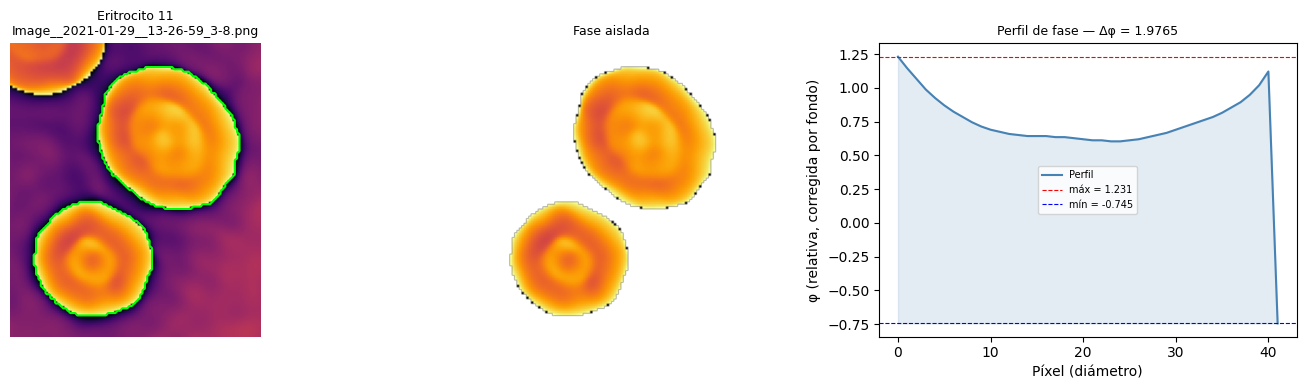

  Guardado: /content/data/processed/heuristica_validacion/annotated_Image__2021-01-29__13-26-59_3-8.png


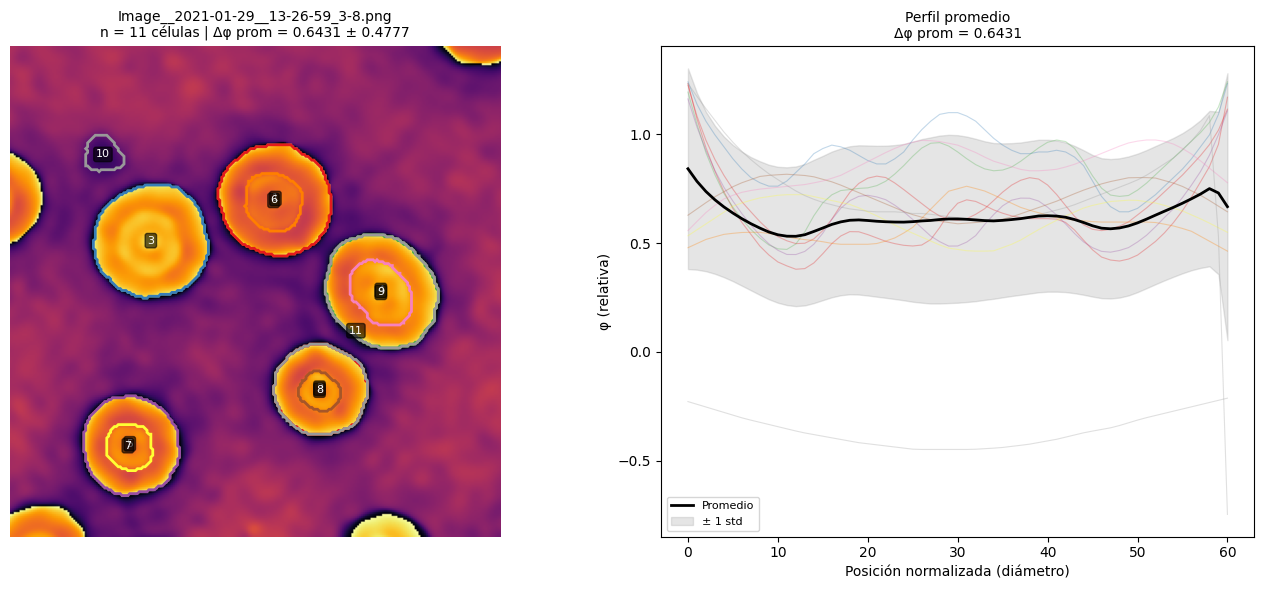


Imagen 4/8: Image__2021-01-29__13-12-01_4-11.png
  Máscaras SAM crudas: 8
  Eritrocitos válidos: 2


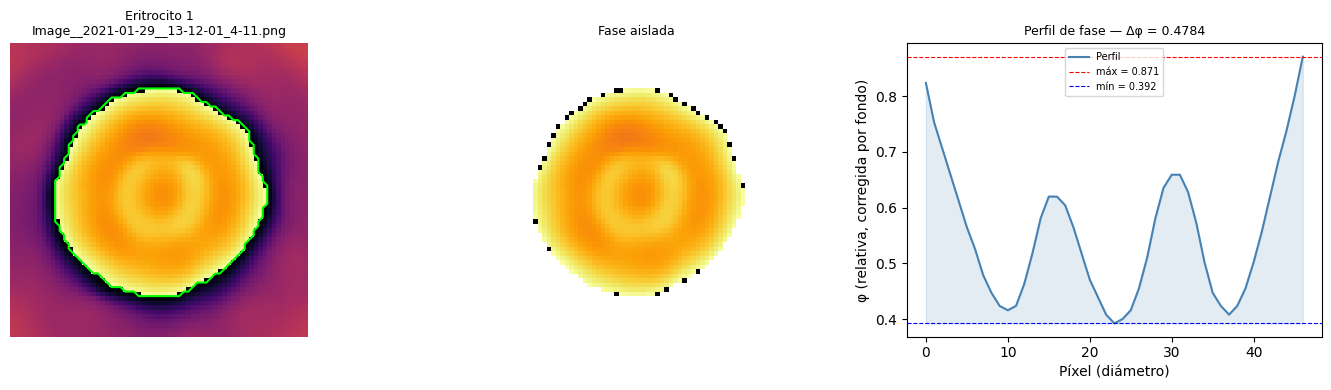

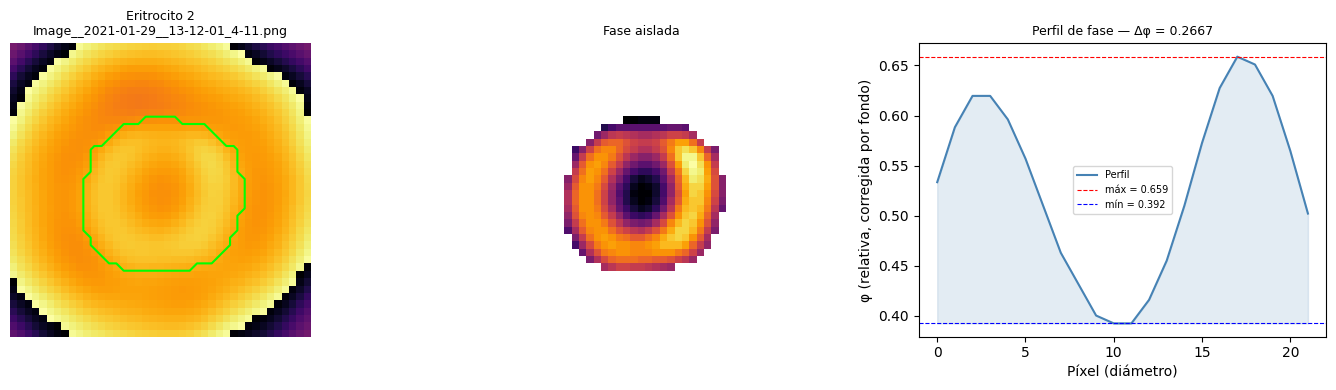

  Guardado: /content/data/processed/heuristica_validacion/annotated_Image__2021-01-29__13-12-01_4-11.png


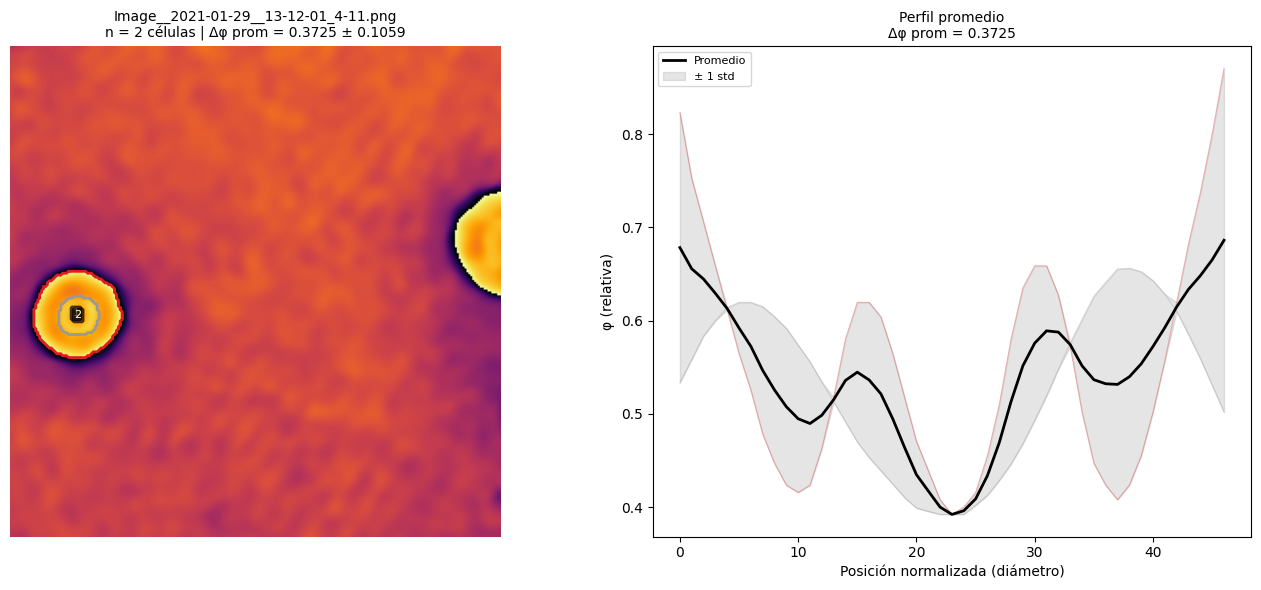


Imagen 5/8: Image__2021-01-29__13-12-45_2-1.png
  Máscaras SAM crudas: 12
  Eritrocitos válidos: 2


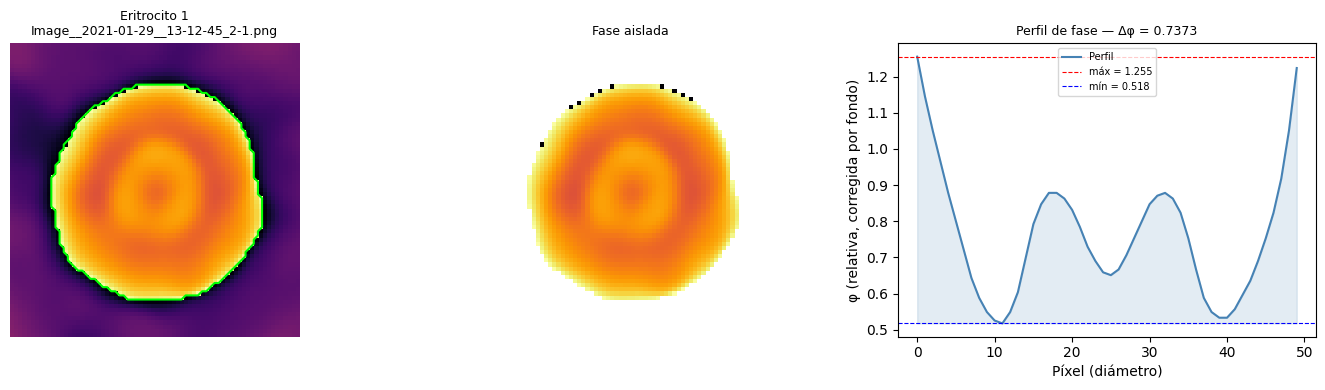

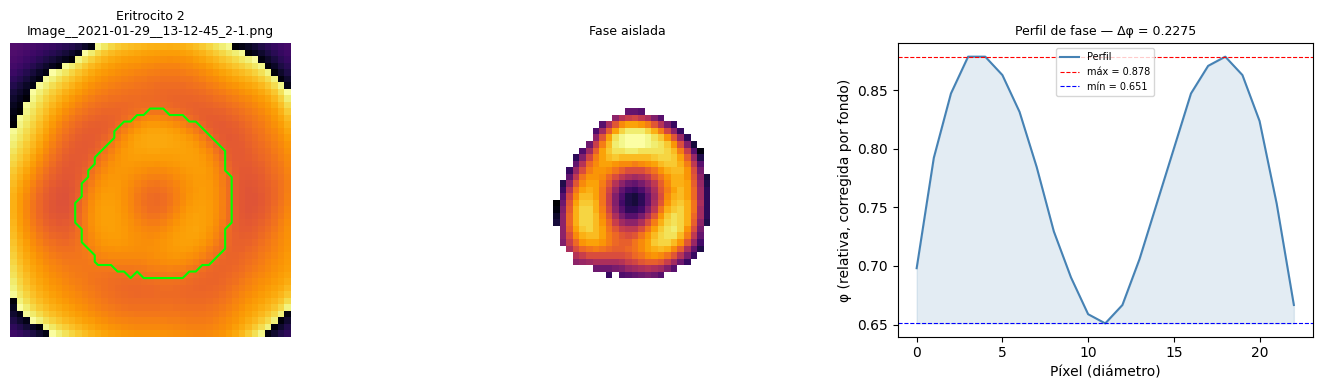

  Guardado: /content/data/processed/heuristica_validacion/annotated_Image__2021-01-29__13-12-45_2-1.png


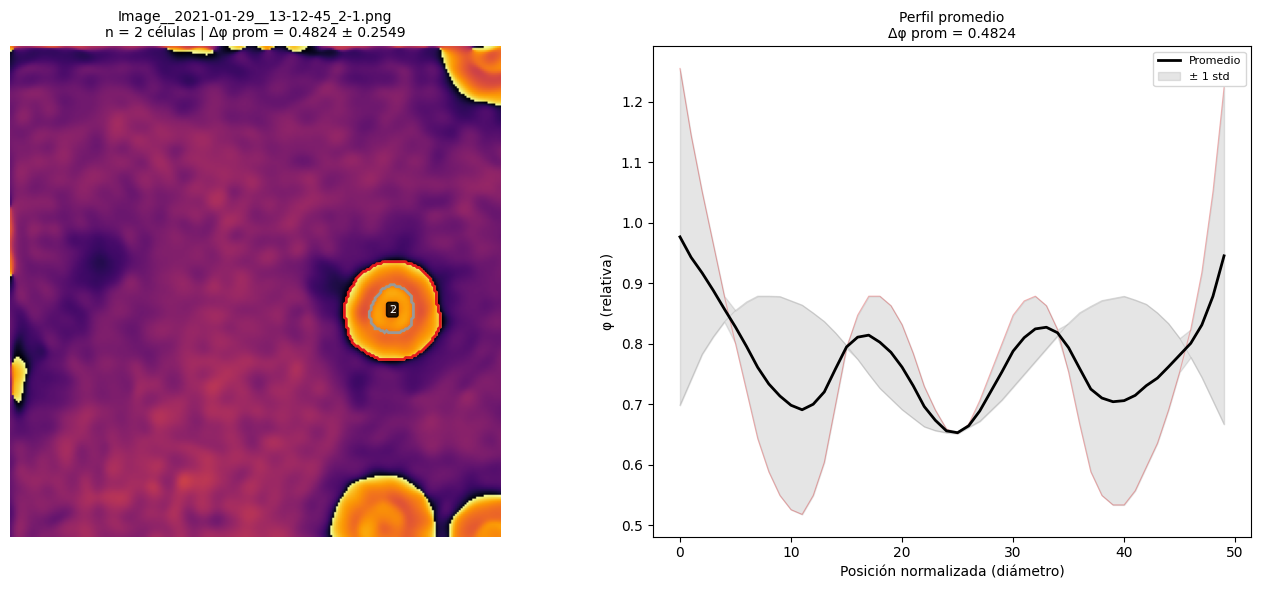


Imagen 6/8: Image__2021-01-28__16-04-31_3-3.png
  Máscaras SAM crudas: 6
  Eritrocitos válidos: 3


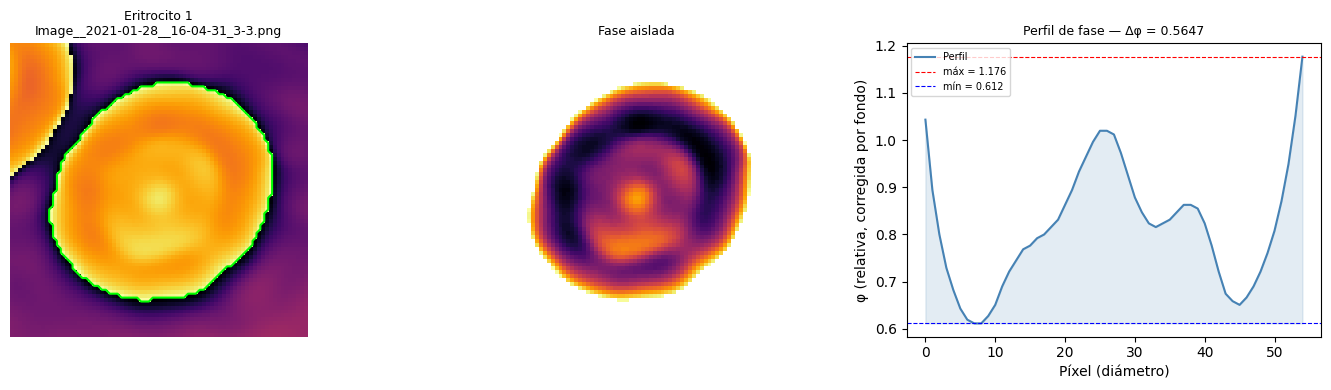

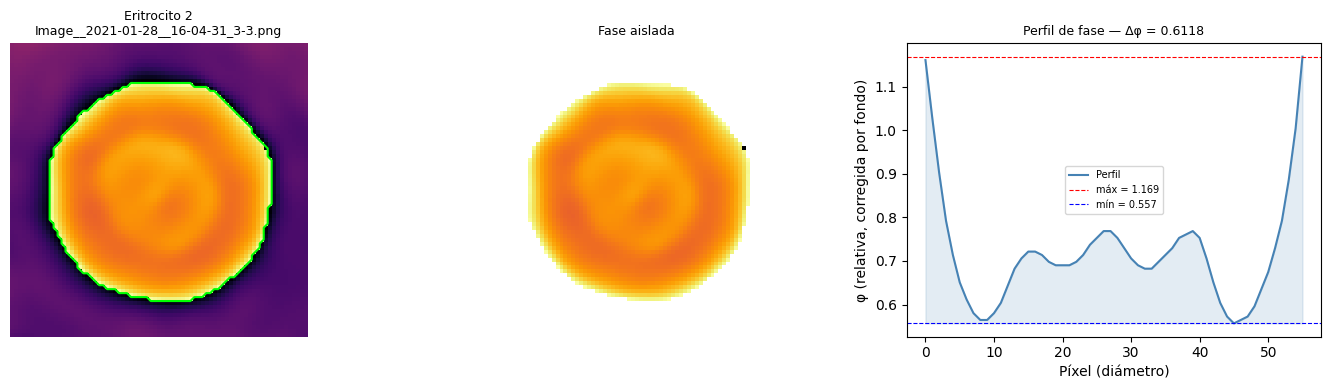

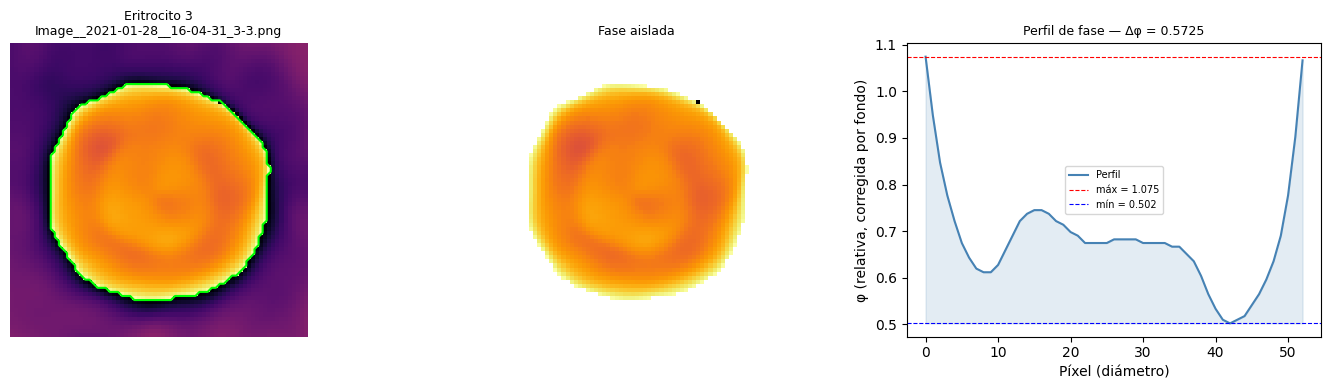

  Guardado: /content/data/processed/heuristica_validacion/annotated_Image__2021-01-28__16-04-31_3-3.png


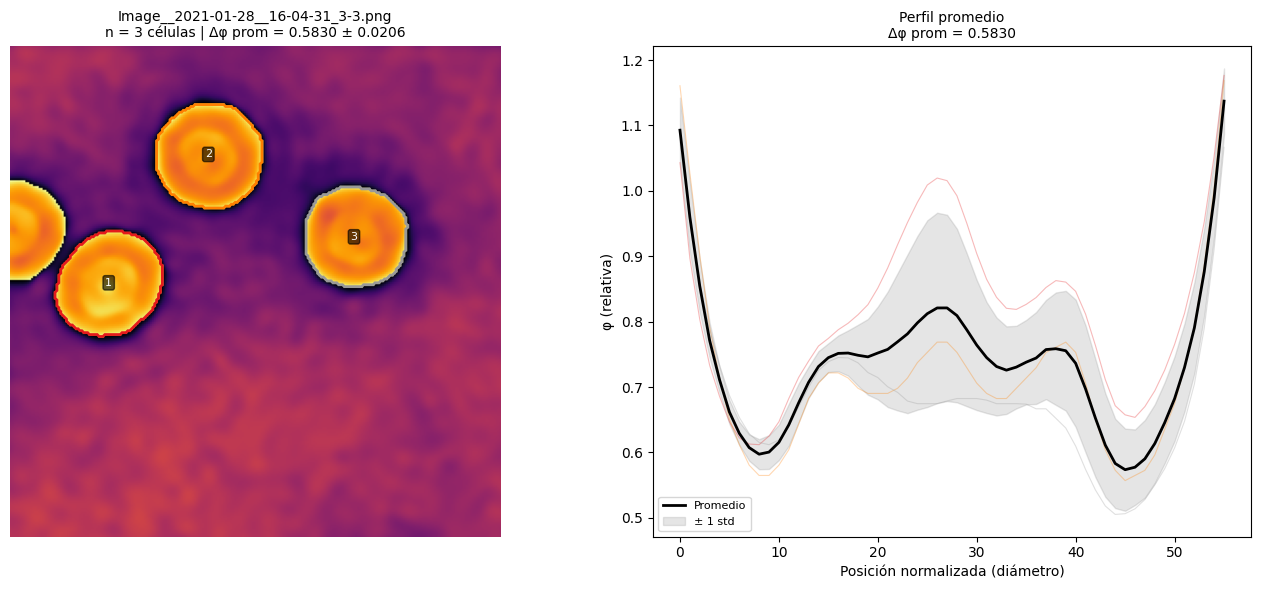


Imagen 7/8: Image__2021-01-29__13-15-19_3-6.png
  Máscaras SAM crudas: 27
  Eritrocitos válidos: 11


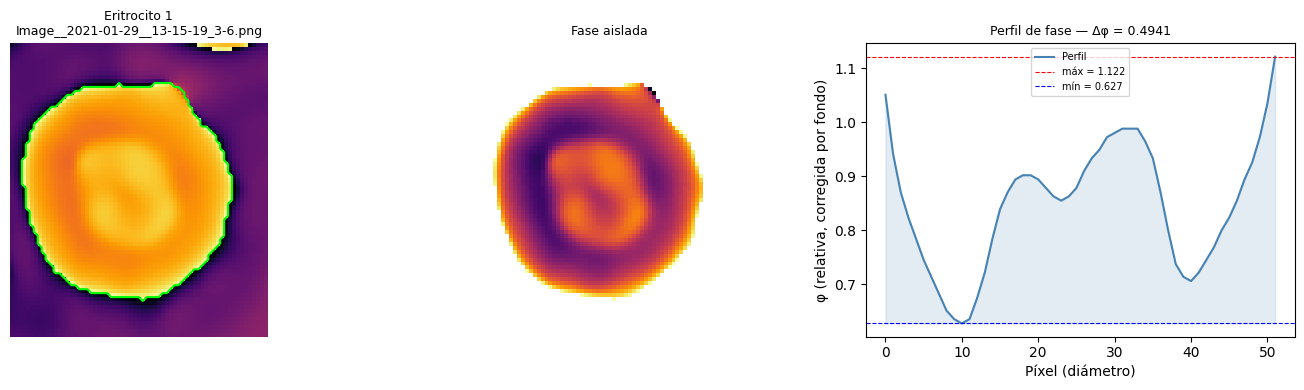

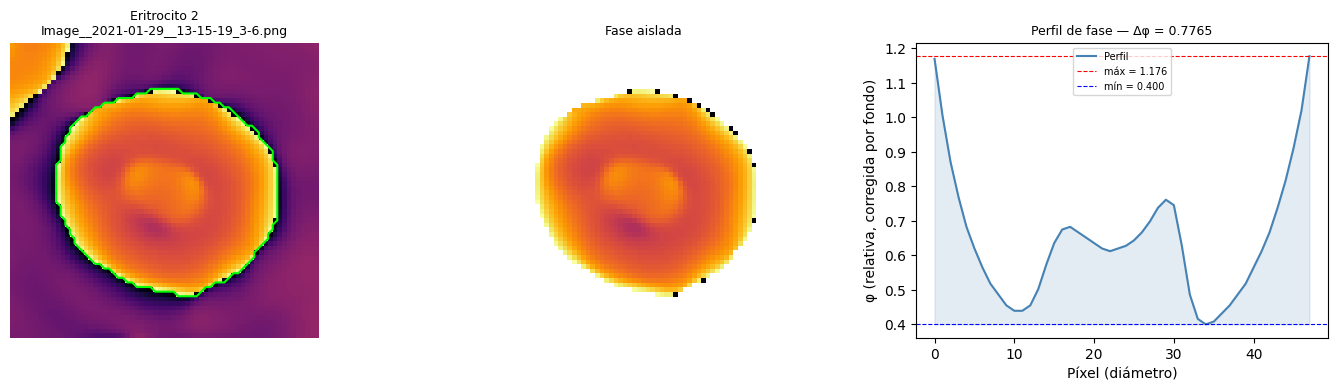

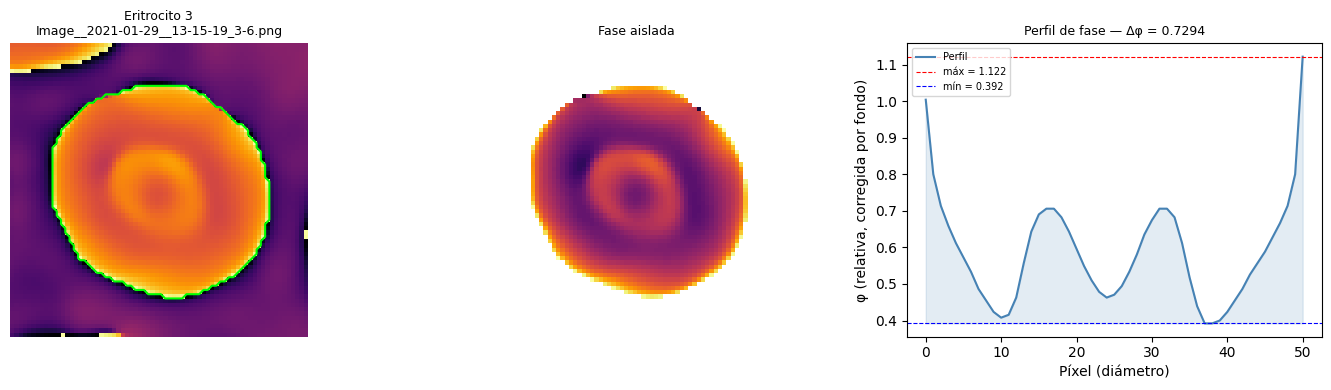

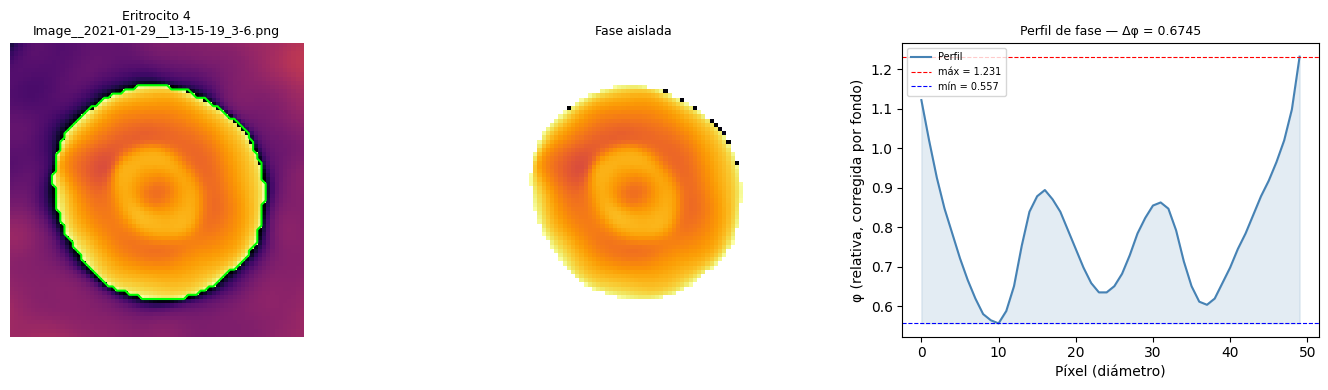

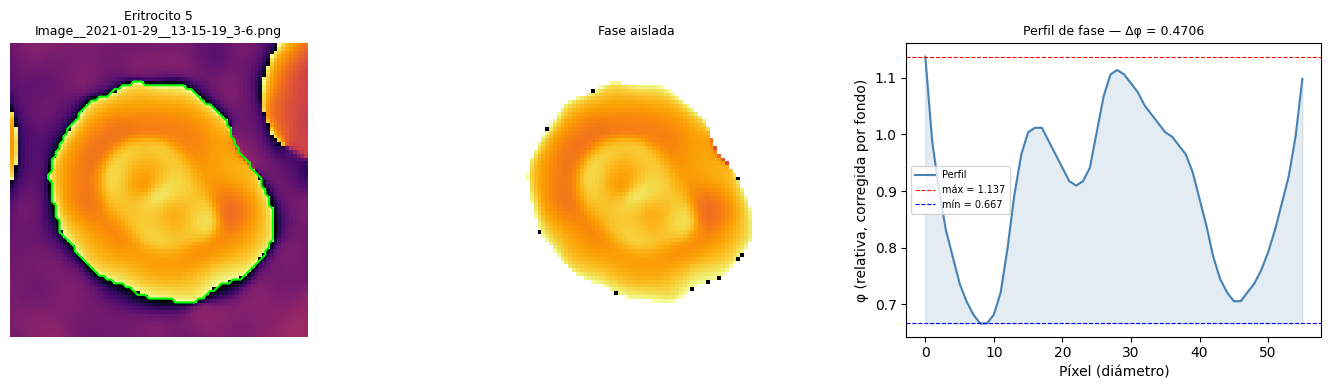

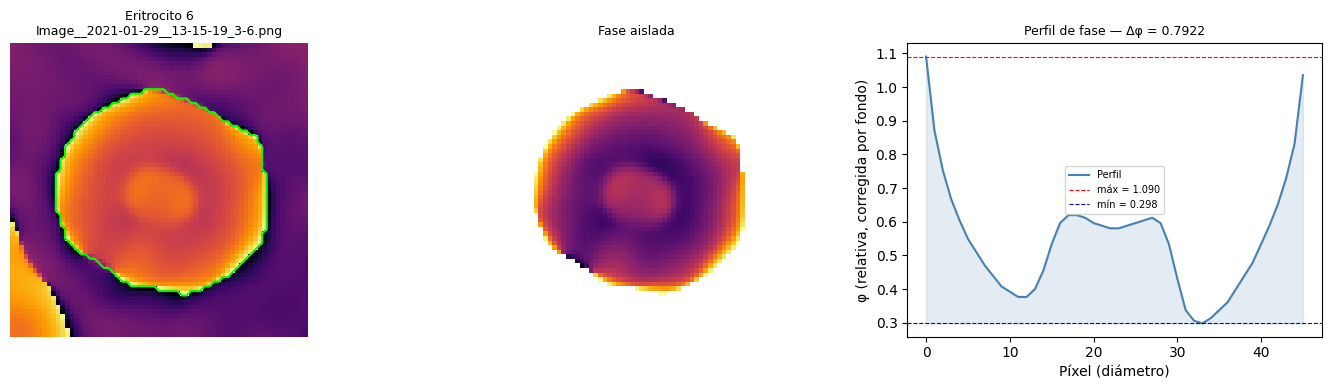

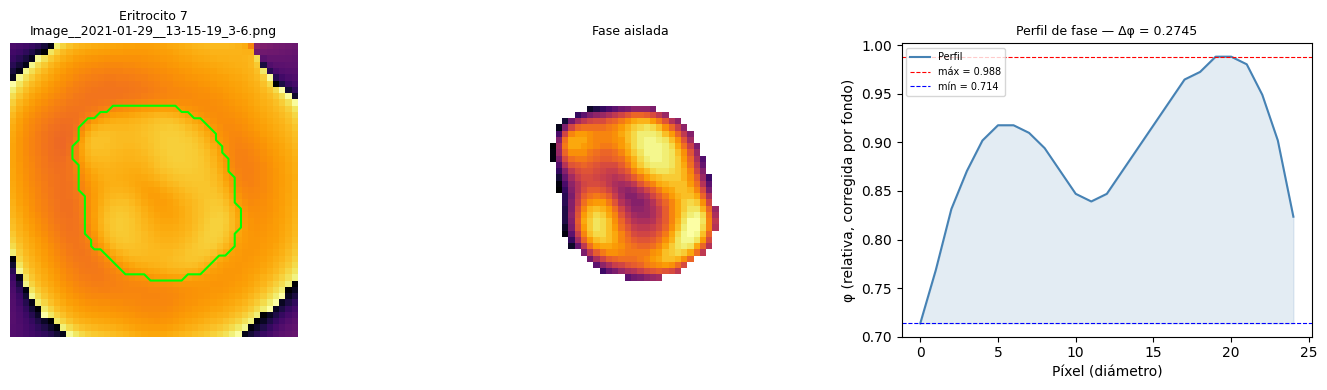

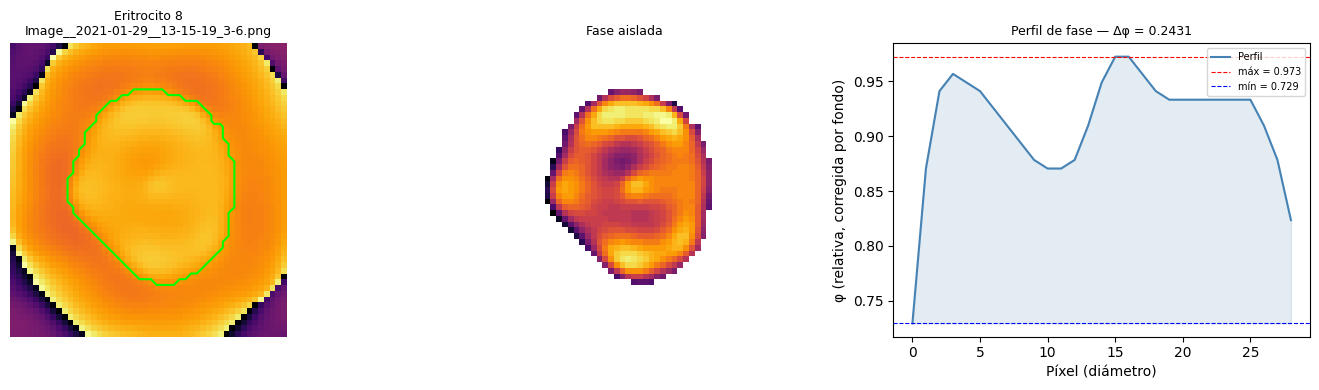

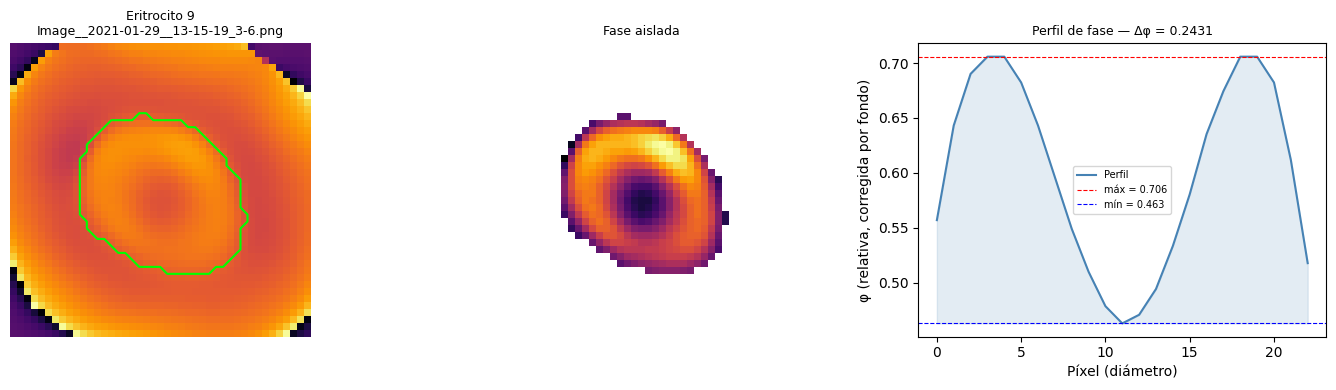

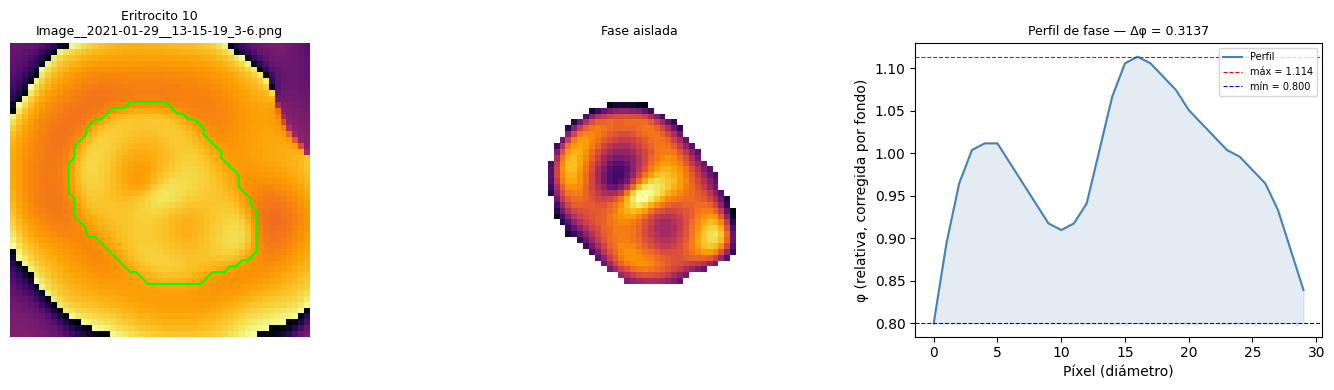

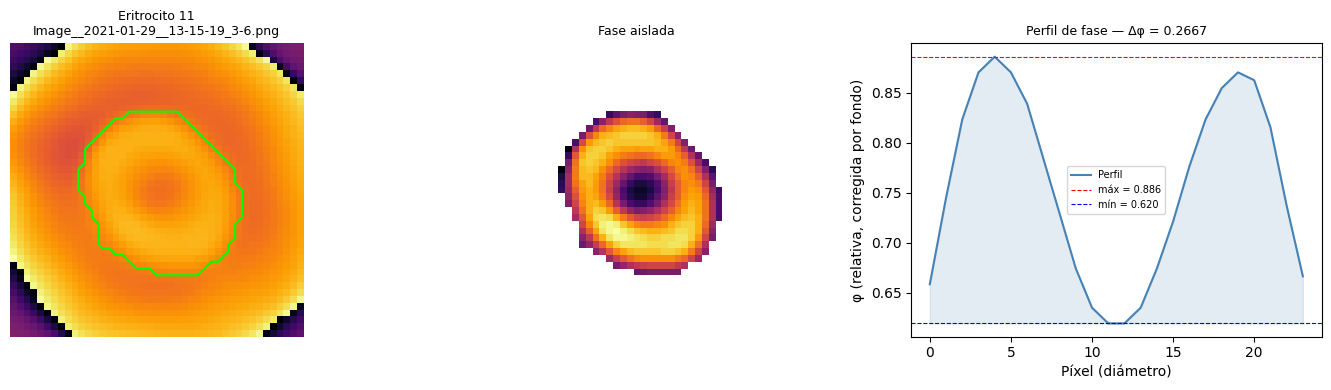

  Guardado: /content/data/processed/heuristica_validacion/annotated_Image__2021-01-29__13-15-19_3-6.png


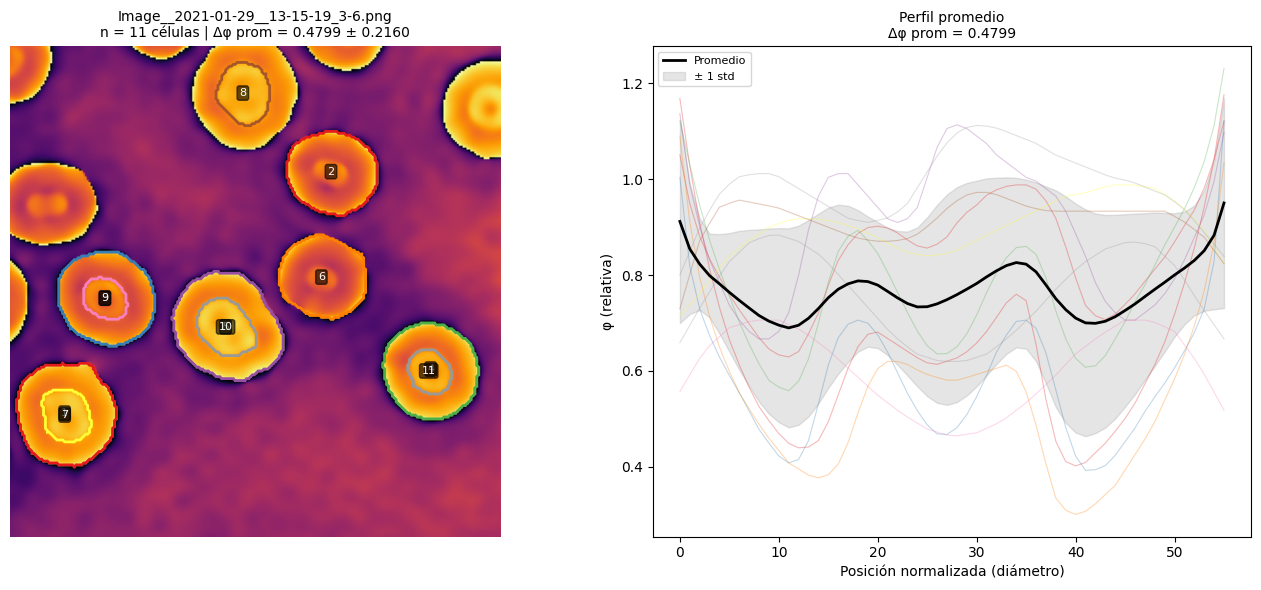


Imagen 8/8: Image__2021-01-29__12-53-41_1-6.png
  Máscaras SAM crudas: 16
  Eritrocitos válidos: 6


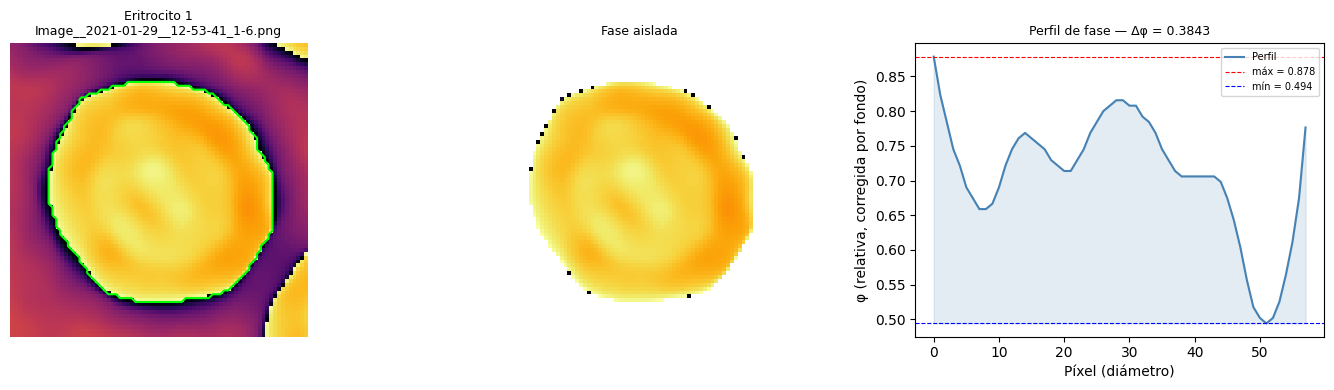

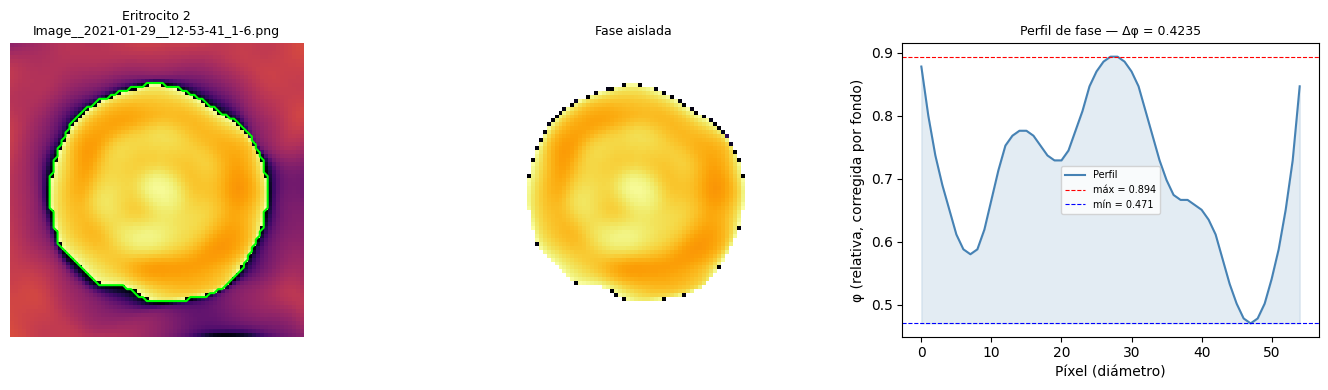

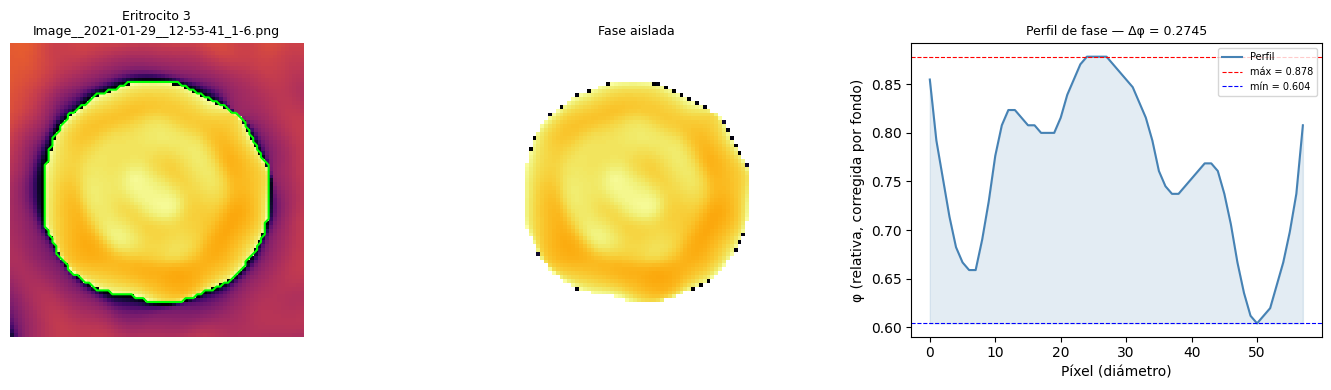

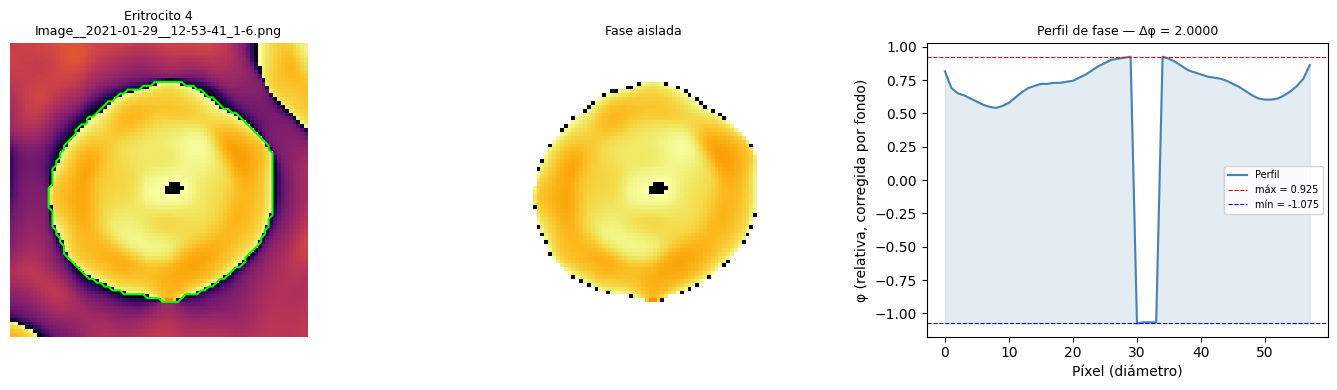

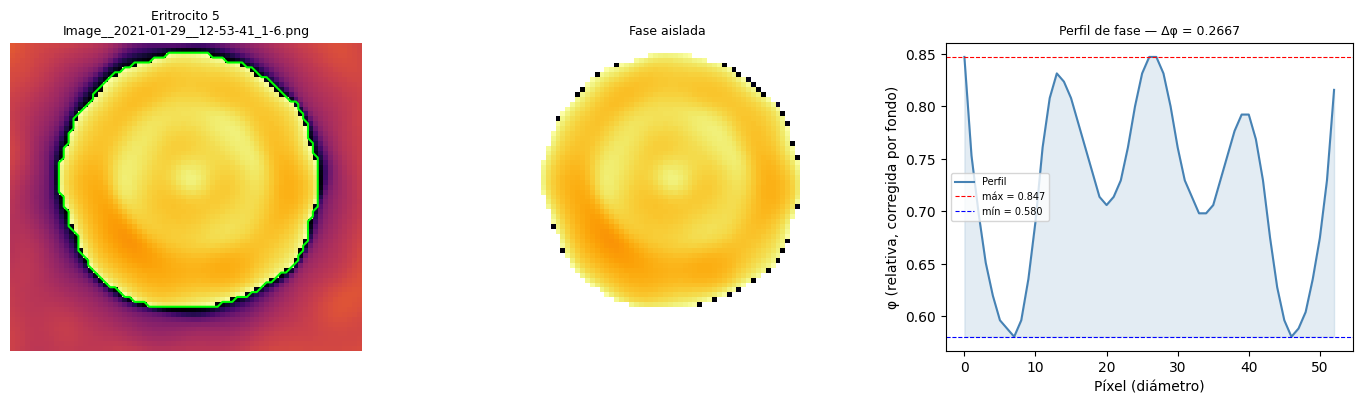

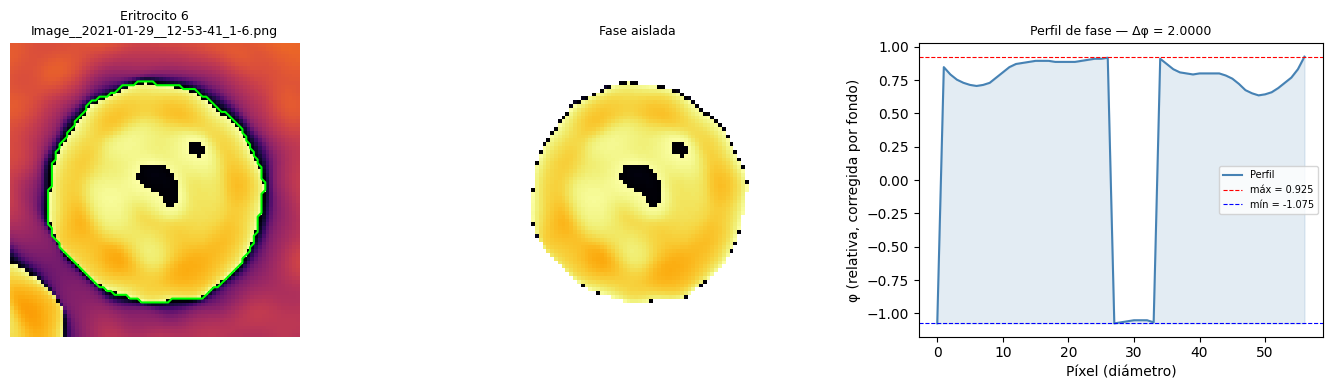

  Guardado: /content/data/processed/heuristica_validacion/annotated_Image__2021-01-29__12-53-41_1-6.png


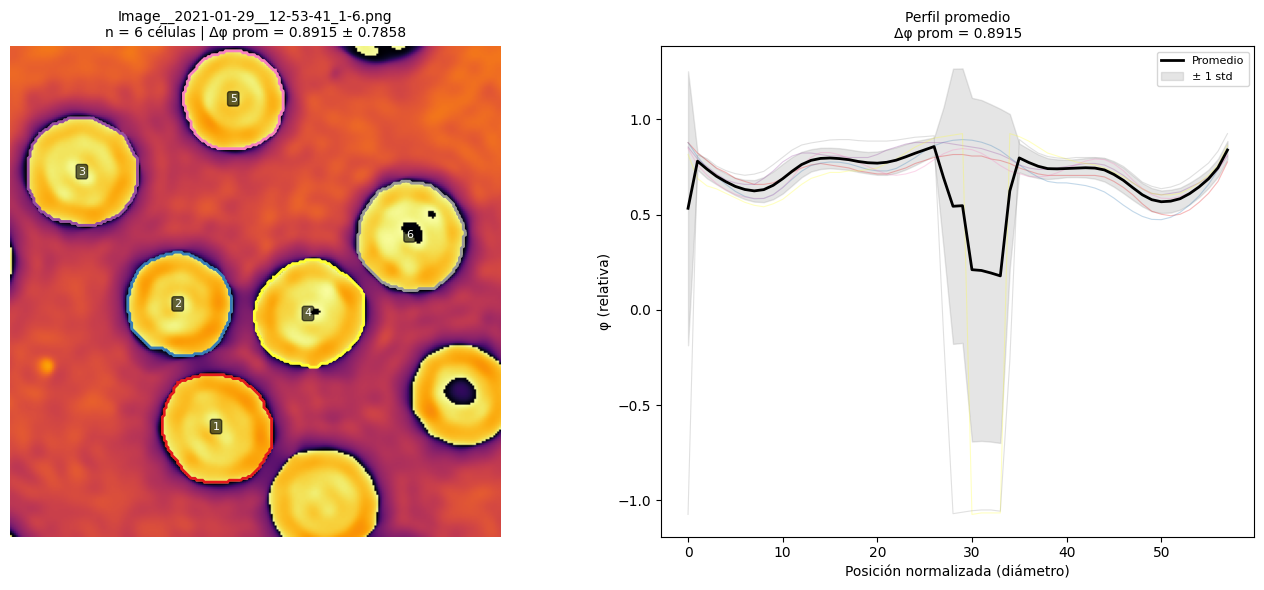


Procesamiento completado: 8 imágenes.


In [13]:
# Directorio para guardar imágenes anotadas
SAVE_DIR = Path('/content/data/processed/heuristica_validacion')
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Acumuladores de resultados
all_results = []         # una fila por imagen
all_cell_results = []    # una fila por célula

for img_idx, (_, row) in enumerate(sample_df.iterrows()):
    img_path = IMG_ROOT / row['file']
    img_name = Path(row['file']).name

    print(f'\n{"="*70}')
    print(f'Imagen {img_idx + 1}/{len(sample_df)}: {img_name}')
    print(f'{"="*70}')

    # Cargar imagen
    gray = np.array(Image.open(img_path).convert('L'))
    phi = to_phase(gray)   # [-1, 1]

    # SAM requiere entrada RGB (H, W, 3) en uint8
    rgb_for_sam = np.stack([gray, gray, gray], axis=-1)

    #  Generar y filtrar máscaras
    raw_masks = mask_generator.generate(rgb_for_sam)
    cell_masks = filter_cell_masks(raw_masks)

    print(f'  Máscaras SAM crudas: {len(raw_masks)}')
    print(f'  Eritrocitos válidos: {len(cell_masks)}')

    if len(cell_masks) == 0:
        print('  Sin eritrocitos detectados en esta imagen. Se registra con n_cells=0.')
        all_results.append({
            'img_name': img_name,
            'n_cells': 0,
            'delta_phi_mean': np.nan,
            'delta_phi_std': np.nan,
            'delta_phi_min': np.nan,
            'delta_phi_max': np.nan,
        })
        continue

    #  Máscara global (unión de todas las células) para el fondo
    all_cells_mask = np.zeros_like(gray, dtype=bool)
    for m in cell_masks:
        all_cells_mask |= m['segmentation']

    # Perfil y delta por célula
    profiles = []
    deltas = []
    centroids = []

    for cell_id, m in enumerate(cell_masks, 1):
        seg = m['segmentation']

        profile, delta_phi, centroid, bg_val = extract_phase_profile_bg_global(
            phi, seg, all_cells_mask
        )

        profiles.append(profile)
        deltas.append(delta_phi)
        centroids.append(centroid)

        all_cell_results.append({
            'img_name': img_name,
            'cell_id': cell_id,
            'delta_phi': delta_phi,
            'profile_len': len(profile),
            'area_px': int(seg.sum()),
            'circularity': circularity(seg),
            'centroid_y': centroid[0],
            'centroid_x': centroid[1],
            'bg_value': bg_val,
        })

        # Visualización individual por célula
        plot_cell_panel(phi, seg, profile, delta_phi, centroid, cell_id, img_name)

    # Imagen anotada con promedios
    mean_d, std_d = annotate_image(
        phi, cell_masks, deltas, profiles, centroids,
        img_name, save_dir=SAVE_DIR
    )

    all_results.append({
        'img_name': img_name,
        'n_cells': len(cell_masks),
        'delta_phi_mean': mean_d,
        'delta_phi_std': std_d,
        'delta_phi_min': min(deltas),
        'delta_phi_max': max(deltas),
    })

print(f'\n{"="*70}')
print(f'Procesamiento completado: {len(sample_df)} imágenes.')
print(f'{"="*70}')

## 5. Resumen

In [14]:
#  Tabla resumen por imagen
df_img = pd.DataFrame(all_results)
print('Resultados por imagen:')
print(df_img.to_string(index=False))

valid_imgs = df_img.dropna(subset=['delta_phi_mean'])
print(f'\n──────────────────────────────────────────────')
print(f'Imágenes procesadas con células: {len(valid_imgs)} / {len(df_img)}')
print(f'Δφ promedio general: {valid_imgs["delta_phi_mean"].mean():.4f}')
print(f'Δφ std general:      {valid_imgs["delta_phi_mean"].std():.4f}')
print(f'Células totales:     {valid_imgs["n_cells"].sum()}')
print(f'──────────────────────────────────────────────')

Resultados por imagen:
                            img_name  n_cells  delta_phi_mean  delta_phi_std  delta_phi_min  delta_phi_max
 Image__2021-01-29__12-36-21_4-3.png        8        0.479412       0.235472       0.156863       0.784314
 Image__2021-01-29__13-12-01_4-1.png        4        0.364706       0.092552       0.235294       0.470588
 Image__2021-01-29__13-26-59_3-8.png       11        0.643137       0.477747       0.227451       1.976471
Image__2021-01-29__13-12-01_4-11.png        2        0.372549       0.105882       0.266667       0.478431
 Image__2021-01-29__13-12-45_2-1.png        2        0.482353       0.254902       0.227451       0.737255
 Image__2021-01-28__16-04-31_3-3.png        3        0.583007       0.020586       0.564706       0.611765
 Image__2021-01-29__13-15-19_3-6.png       11        0.479857       0.216009       0.243137       0.792157
 Image__2021-01-29__12-53-41_1-6.png        6        0.891503       0.785798       0.266667       2.000000

─────────────

In [15]:
# Tabla resumen por célula
df_cell = pd.DataFrame(all_cell_results)
print(f'Total de células segmentadas: {len(df_cell)}')
print(f'\nEstadísticas del delta de fase por célula:')
print(df_cell['delta_phi'].describe().to_string())
df_cell.head(10)

Total de células segmentadas: 47

Estadísticas del delta de fase por célula:
count    47.000000
mean      0.562870
std       0.428708
min       0.156863
25%       0.270588
50%       0.470588
75%       0.721569
max       2.000000


,img_name,cell_id,delta_phi,profile_len,area_px,circularity,centroid_y,centroid_x,bg_value
0,Image__2021-01-29__12-36-21_4-3.png,1,0.564706,52,2119,0.890662,28,130,-0.247059
1,Image__2021-01-29__12-36-21_4-3.png,2,0.784314,50,1981,0.887940,139,188,-0.247059
2,Image__2021-01-29__12-36-21_4-3.png,3,0.745098,49,1937,0.869808,106,90,-0.247059
3,Image__2021-01-29__12-36-21_4-3.png,4,0.713725,53,2131,0.894173,133,37,-0.247059
4,Image__2021-01-29__12-36-21_4-3.png,5,0.305882,22,373,0.862762,133,39,-0.247059
5,Image__2021-01-29__12-36-21_4-3.png,6,0.337255,24,456,0.885170,29,130,-0.247059
6,Image__2021-01-29__12-36-21_4-3.png,7,0.227451,20,317,0.843970,140,188,-0.247059
7,Image__2021-01-29__12-36-21_4-3.png,8,0.156863,21,429,0.811005,26,214,-0.247059
8,Image__2021-01-29__13-12-01_4-1.png,1,0.470588,54,2137,0.867253,151,74,0.200000
9,Image__2021-01-29__13-12-01_4-1.png,2,0.431373,47,1711,0.876342,203,107,0.200000


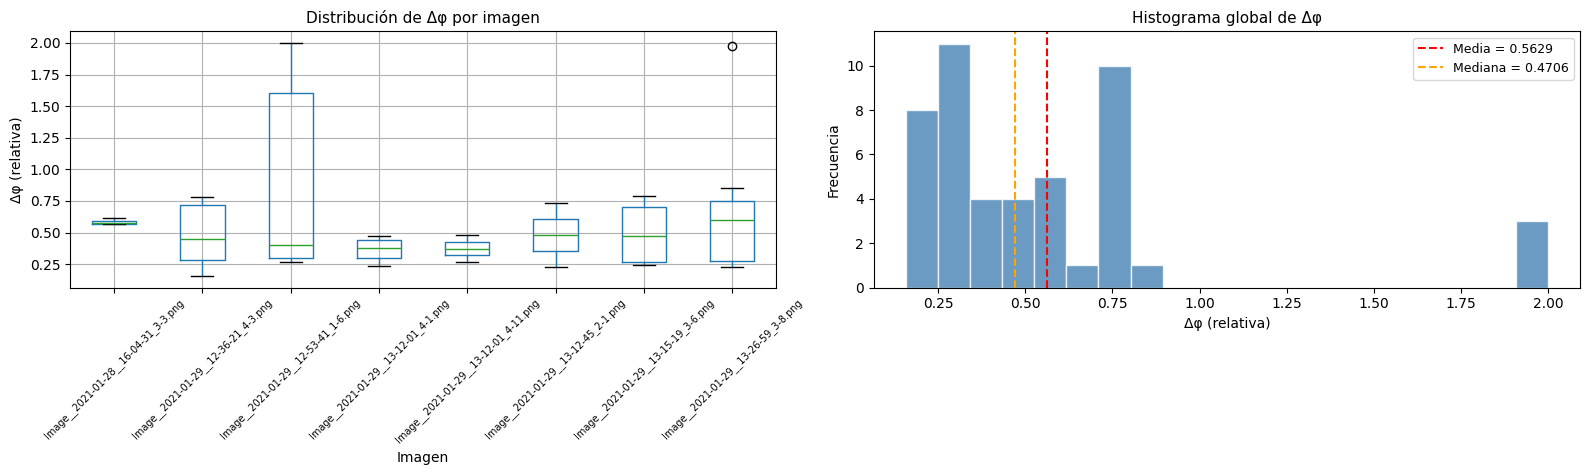

In [16]:
# Boxplot: distribución de Δφ por imagen
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Boxplot por imagen
ax = axes[0]
if len(df_cell) > 0:
    df_cell.boxplot(column='delta_phi', by='img_name', ax=ax, rot=45)
    ax.set_title('Distribución de Δφ por imagen', fontsize=11)
    ax.set_xlabel('Imagen')
    ax.set_ylabel('Δφ (relativa)')
    plt.sca(ax)
    plt.xticks(fontsize=7)
    fig.suptitle('')  # quitar título automático de pandas

# Histograma global de Δφ
ax = axes[1]
if len(df_cell) > 0:
    ax.hist(df_cell['delta_phi'], bins=20, color='steelblue', edgecolor='white', alpha=0.8)
    ax.axvline(df_cell['delta_phi'].mean(), color='red', ls='--', lw=1.5,
               label=f'Media = {df_cell["delta_phi"].mean():.4f}')
    ax.axvline(df_cell['delta_phi'].median(), color='orange', ls='--', lw=1.5,
               label=f'Mediana = {df_cell["delta_phi"].median():.4f}')
    ax.set_title('Histograma global de Δφ', fontsize=11)
    ax.set_xlabel('Δφ (relativa)')
    ax.set_ylabel('Frecuencia')
    ax.legend(fontsize=9)

plt.tight_layout()
fig.savefig(SAVE_DIR / 'resumen_delta_phi.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

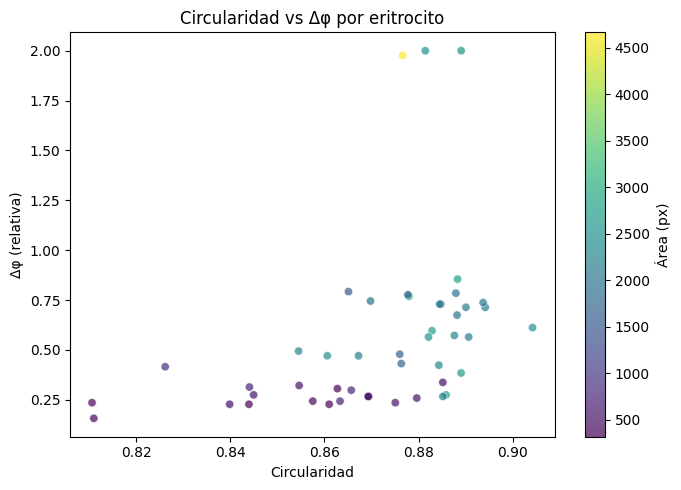

In [17]:
# Scatter: circularidad vs delta de fase
if len(df_cell) > 0:
    fig, ax = plt.subplots(figsize=(7, 5))
    sc = ax.scatter(df_cell['circularity'], df_cell['delta_phi'],
                    c=df_cell['area_px'], cmap='viridis', alpha=0.7, edgecolors='white', lw=0.5)
    plt.colorbar(sc, ax=ax, label='Área (px)')
    ax.set_xlabel('Circularidad')
    ax.set_ylabel('Δφ (relativa)')
    ax.set_title('Circularidad vs Δφ por eritrocito')
    plt.tight_layout()
    fig.savefig(SAVE_DIR / 'circularity_vs_delta.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [18]:
# Guardar CSV de resultados
df_img.to_csv(SAVE_DIR / 'resultados_por_imagen.csv', index=False)
df_cell.to_csv(SAVE_DIR / 'resultados_por_celula.csv', index=False)
print(f'Resultados guardados en {SAVE_DIR}:')
for f in sorted(SAVE_DIR.iterdir()):
    size_kb = f.stat().st_size / 1024
    print(f'  {f.name}  ({size_kb:.1f} KB)')

Resultados guardados en /content/data/processed/heuristica_validacion:
  annotated_Image__2021-01-28__16-04-31_3-3.png  (468.1 KB)
  annotated_Image__2021-01-29__12-36-21_4-3.png  (570.8 KB)
  annotated_Image__2021-01-29__12-53-41_1-6.png  (580.0 KB)
  annotated_Image__2021-01-29__13-12-01_4-1.png  (511.4 KB)
  annotated_Image__2021-01-29__13-12-01_4-11.png  (422.0 KB)
  annotated_Image__2021-01-29__13-12-45_2-1.png  (448.0 KB)
  annotated_Image__2021-01-29__13-15-19_3-6.png  (659.7 KB)
  annotated_Image__2021-01-29__13-26-59_3-8.png  (559.2 KB)
  circularity_vs_delta.png  (61.6 KB)
  resultados_por_celula.csv  (5.2 KB)
  resultados_por_imagen.csv  (1.0 KB)
  resumen_delta_phi.png  (101.8 KB)


## 6. Copiar resultados a Drive

In [19]:
import shutil

DRIVE_OUT = Path('/content/drive/MyDrive/dl-qpi/data/processed/heuristica_validacion')
if DRIVE_OUT.exists():
    shutil.rmtree(DRIVE_OUT)
shutil.copytree(SAVE_DIR, DRIVE_OUT)
print(f'Resultados copiados a Drive: {DRIVE_OUT}')
for f in sorted(DRIVE_OUT.iterdir()):
    print(f'  {f.name}')

Resultados copiados a Drive: /content/drive/MyDrive/dl-qpi/data/processed/heuristica_validacion
  annotated_Image__2021-01-28__16-04-31_3-3.png
  annotated_Image__2021-01-29__12-36-21_4-3.png
  annotated_Image__2021-01-29__12-53-41_1-6.png
  annotated_Image__2021-01-29__13-12-01_4-1.png
  annotated_Image__2021-01-29__13-12-01_4-11.png
  annotated_Image__2021-01-29__13-12-45_2-1.png
  annotated_Image__2021-01-29__13-15-19_3-6.png
  annotated_Image__2021-01-29__13-26-59_3-8.png
  circularity_vs_delta.png
  resultados_por_celula.csv
  resultados_por_imagen.csv
  resumen_delta_phi.png


## Checklist de entrega (issue #8)

| Criterio | Estado |
|---|---|
| Segmenta eritrocitos individuales en ≥ 5 imágenes de fase | Listo :) |
| Calcula y grafica perfil de fase y $\Delta\phi$ por eritrocito | Realizado |
| Muestra reconstrucción visual de cada eritrocito individual | Hecho |
| Genera versión anotada con promedio de perfil/$\Delta\phi$ por imagen | Completo |